# Графический подход к множественному тестированию в A/B-экспериментах

## 0. Реализация класса `Graph`

In [ ]:
import numpy as np
import networkx as nx
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from fractions import Fraction
from IPython.display import display, Markdown, Math


def format_fraction(value, limit=1000):
    """Преобразует float в строку с обыкновенной дробью."""
    if value == 0:
        return "0"
    if value == 1:
        return "1"
    frac = Fraction(value).limit_denominator(limit)
    return f"{frac.numerator}/{frac.denominator}"

def format_alpha(weight, mode="fraction", alpha_global=0.05):
    """
    Форматирует вес вершины в зависимости от режима отображения.
    mode: "fraction" – абсолютная дробь от α
          "symbolic" – доля от общего α (например, α/2, 2α)
    """
    if weight == 0:
        return "0"
    if mode == "fraction":
        return format_fraction(weight)
    elif mode == "symbolic":
        ratio = weight / alpha_global
        frac = Fraction(ratio).limit_denominator(100)
        if frac.numerator == frac.denominator:
            return f"α"
        elif frac.denominator == 1:
            return f"{frac.numerator}α"
        else:
            return f"α/{frac.denominator}"
    else:
        return f"{weight:.4f}"


def update_graph(alpha_vec, G_matrix, rejected_idx):
    """
    Обновляет граф после отвержения гипотезы rejected_idx.
    Реализует формулы (2)-(3) из статьи Bretz et al. (2009).
    """
    m = len(alpha_vec)
    new_alpha = np.copy(alpha_vec)
    new_G = np.copy(G_matrix)

    rejected_alpha = alpha_vec[rejected_idx]
    new_alpha[rejected_idx] = 0.0

    # Перераспределение уровня по исходящим рёбрам (БЕЗ условия new_alpha[l] > 0)
    for l in range(m):
        if l != rejected_idx:
            new_alpha[l] += rejected_alpha * G_matrix[rejected_idx, l]

    # Обновление матрицы переходов
    for l in range(m):
        for k in range(m):
            if l != k and l != rejected_idx and k != rejected_idx:
                denominator = 1.0 - G_matrix[l, rejected_idx] * G_matrix[rejected_idx, l]
                if denominator > 0:
                    numerator = G_matrix[l, k] + G_matrix[l, rejected_idx] * G_matrix[rejected_idx, k]
                    new_G[l, k] = numerator / denominator
                else:
                    new_G[l, k] = 0.0
            else:
                new_G[l, k] = 0.0

    new_G[rejected_idx, :] = 0.0
    new_G[:, rejected_idx] = 0.0

    # Нормализация строк (сумма ≤ 1)
    for l in range(m):
        row_sum = np.sum(new_G[l, :])
        if row_sum > 1.0:
            new_G[l, :] /= row_sum

    return new_alpha, new_G


def draw_graph(alpha_vec, G_matrix,
               title="Графическое представление гипотез",
               width=800, height=600,
               show_alpha_values=True,
               alpha_symbol="α",
               node_labels=None,
               alpha_display_mode="fraction",
               alpha_global=0.05):
    """
    Строит интерактивный ориентированный граф гипотез.

    Параметры:
    - alpha_vec: вектор весов для отображаемых вершин
    - G_matrix: матрица переходов (квадратная, размер = len(alpha_vec))
    - node_labels: список строк с подписями вершин (если None, H1, H2, ...)
    - alpha_display_mode: "fraction" (абсолютные дроби) или "symbolic" (доли от α)
    - alpha_global: общий уровень α для символического режима
    """
    m = len(alpha_vec)
    if node_labels is None:
        node_labels = [f"H{i+1}" for i in range(m)]

    G = nx.DiGraph()
    for i in range(m):
        G.add_node(i, weight=alpha_vec[i], label=node_labels[i])
    for i in range(m):
        for j in range(m):
            if G_matrix[i, j] > 0 and i != j:
                G.add_edge(i, j, weight=G_matrix[i, j])

    # Расположение вершин
    if m == 1:
        pos = {0: np.array([0, 0])}
    elif m == 2:
        pos = {0: np.array([-1, 0]), 1: np.array([1, 0])}
    elif m == 3:
        pos = {0: np.array([0, np.sqrt(3)/2]),
               1: np.array([-0.8, -np.sqrt(3)/4]),
               2: np.array([0.8, -np.sqrt(3)/4])}
    elif m == 4:
        pos = {0: np.array([-1, 1]),
               1: np.array([1, 1]),
               2: np.array([1, -1]),
               3: np.array([-1, -1])}
    else:
        pos = nx.kamada_kawai_layout(G)

    fig = go.Figure()
    vertex_colors = ['#4C78A8', '#F58518', '#E45756', '#72B7B2',
                     '#54A24B', '#EECA3B', '#B279A2', '#FF9DA6']

    drawn_reverse = set()

    # Вспомогательная функция для прямого ребра (линия + стрелка + подпись)
    def add_edge_line(x0, y0, x1, y1, weight_str, u_label, v_label):
        fig.add_trace(go.Scatter(
            x=[x0, x1], y=[y0, y1],
            mode='lines',
            line=dict(color='rgba(100,100,100,0.7)', width=2),
            hoverinfo='text',
            text=f"{u_label} → {v_label}<br>Вес: {weight_str}",
            showlegend=False
        ))
        fig.add_annotation(
            x=x1, y=y1,
            ax=x0, ay=y0,
            xref='x', yref='y',
            axref='x', ayref='y',
            showarrow=True,
            arrowhead=2,
            arrowsize=1.5,
            arrowwidth=2,
            arrowcolor='rgba(100,100,100,0.7)',
            text=""
        )
        mid_x, mid_y = (x0+x1)/2, (y0+y1)/2
        dx, dy = x1-x0, y1-y0
        dist = np.hypot(dx, dy)
        if dist > 0:
            offset_x = -dy/dist * 0.15
            offset_y = dx/dist * 0.15
        else:
            offset_x, offset_y = 0, 0
        fig.add_annotation(
            x=mid_x+offset_x, y=mid_y+offset_y,
            text=f"<b>{weight_str}</b>",
            showarrow=False,
            font=dict(size=11, color='#2c3e50'),
            bgcolor='rgba(255,255,255,0.9)',
            borderpad=4, borderwidth=1,
            bordercolor='rgba(128,128,128,0.3)'
        )

    # Рёбра
    for u, v in G.edges():
        has_reverse = (v, u) in G.edges()
        if has_reverse and (v, u) in drawn_reverse:
            continue

        x0, y0 = pos[u]
        x1, y1 = pos[v]
        weight = G.edges[u, v]['weight']
        weight_str = format_fraction(weight)

        if has_reverse:
            rev_weight = G.edges[v, u]['weight']
            rev_weight_str = format_fraction(rev_weight)
            curvature = 0.3
            dx = x1 - x0
            dy = y1 - y0
            dist = np.hypot(dx, dy)
            if dist > 0:
                nx_vec = -dy / dist
                ny_vec = dx / dist
            else:
                nx_vec, ny_vec = 0, 0

            # u -> v
            cx1 = (x0 + x1) / 2 + nx_vec * curvature
            cy1 = (y0 + y1) / 2 + ny_vec * curvature
            t = np.linspace(0, 1, 100)
            bx1 = (1-t)**2 * x0 + 2*(1-t)*t * cx1 + t**2 * x1
            by1 = (1-t)**2 * y0 + 2*(1-t)*t * cy1 + t**2 * y1
            fig.add_trace(go.Scatter(x=bx1, y=by1, mode='lines',
                                     line=dict(color='rgba(100,100,100,0.7)', width=2),
                                     hoverinfo='text',
                                     text=f"{node_labels[u]} → {node_labels[v]}<br>Вес: {weight_str}",
                                     showlegend=False))
            fig.add_annotation(x=bx1[-1], y=by1[-1], ax=bx1[-2], ay=by1[-2],
                               showarrow=True, arrowhead=2, arrowsize=1.5,
                               arrowwidth=2, arrowcolor='rgba(100,100,100,0.7)')
            mid1 = len(t)//2
            fig.add_annotation(x=bx1[mid1] + nx_vec*curvature*0.5,
                               y=by1[mid1] + ny_vec*curvature*0.5,
                               text=f"<b>{weight_str}</b>", showarrow=False,
                               font=dict(size=11, color='#2c3e50'),
                               bgcolor='rgba(255,255,255,0.9)',
                               borderpad=4, borderwidth=1,
                               bordercolor='rgba(128,128,128,0.3)')

            # v -> u
            cx2 = (x0 + x1) / 2 - nx_vec * curvature
            cy2 = (y0 + y1) / 2 - ny_vec * curvature
            bx2 = (1-t)**2 * x1 + 2*(1-t)*t * cx2 + t**2 * x0
            by2 = (1-t)**2 * y1 + 2*(1-t)*t * cy2 + t**2 * y0
            fig.add_trace(go.Scatter(x=bx2, y=by2, mode='lines',
                                     line=dict(color='rgba(100,100,100,0.7)', width=2),
                                     hoverinfo='text',
                                     text=f"{node_labels[v]} → {node_labels[u]}<br>Вес: {rev_weight_str}",
                                     showlegend=False))
            fig.add_annotation(x=bx2[-1], y=by2[-1], ax=bx2[-2], ay=by2[-2],
                               showarrow=True, arrowhead=2, arrowsize=1.5,
                               arrowwidth=2, arrowcolor='rgba(100,100,100,0.7)')
            mid2 = len(t)//2
            fig.add_annotation(x=bx2[mid2] - nx_vec*curvature*0.5,
                               y=by2[mid2] - ny_vec*curvature*0.5,
                               text=f"<b>{rev_weight_str}</b>", showarrow=False,
                               font=dict(size=11, color='#2c3e50'),
                               bgcolor='rgba(255,255,255,0.9)',
                               borderpad=4, borderwidth=1,
                               bordercolor='rgba(128,128,128,0.3)')
            drawn_reverse.add((u, v))
        else:
            add_edge_line(x0, y0, x1, y1, weight_str, node_labels[u], node_labels[v])

    # Вершины
    for i in range(m):
        x, y = pos[i]
        weight = alpha_vec[i]
        color = vertex_colors[i % len(vertex_colors)]
        w_str = format_alpha(weight, alpha_display_mode, alpha_global)
        fig.add_trace(go.Scatter(x=[x], y=[y], mode='markers+text',
                                 marker=dict(size=45, color=color,
                                             line=dict(color='white', width=3),
                                             opacity=0.95),
                                 text=f"<b>{node_labels[i]}</b>",
                                 textposition='middle center',
                                 textfont=dict(size=14, color='white'),
                                 hovertext=f"{node_labels[i]}<br>α = {w_str}",
                                 hoverinfo='text',
                                 showlegend=False))
        if show_alpha_values and weight > 0:
            fig.add_annotation(x=x, y=y-0.22, text=f"<b>{w_str}</b>",
                               showarrow=False,
                               font=dict(size=12, color='#2c3e50'),
                               bgcolor='rgba(255,255,255,0.85)',
                               borderpad=4, borderwidth=1,
                               bordercolor='rgba(128,128,128,0.3)')
        elif show_alpha_values:
            fig.add_annotation(x=x, y=y-0.22, text="<b>0</b>",
                               showarrow=False,
                               font=dict(size=12, color='#95a5a6'),
                               bgcolor='rgba(255,255,255,0.85)', borderpad=4)

    fig.update_layout(title=dict(text=title, font=dict(size=18, color='#2c3e50'), x=0.5),
                      width=width, height=height,
                      showlegend=False,
                      plot_bgcolor='rgba(252,252,252,1)',
                      paper_bgcolor='white',
                      xaxis=dict(showgrid=False, zeroline=False, showticklabels=False,
                                 scaleanchor='y', scaleratio=1),
                      yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                      margin=dict(t=80, b=40, l=40, r=40))
    fig.update_xaxes(range=[-1.6, 1.6])
    fig.update_yaxes(range=[-1.4, 1.4])
    return fig


class Graph:
    def __init__(self, m, alpha, alpha_vec, p_values, G_matrix):
        self.m = m
        self.alpha = alpha
        self.alpha_vec0 = np.array(alpha_vec, dtype=float)
        self.p_values = np.array(p_values, dtype=float)
        self.G0 = np.array(G_matrix, dtype=float)

        assert len(self.alpha_vec0) == m
        assert len(self.p_values) == m
        assert self.G0.shape == (m, m)
        assert np.sum(self.alpha_vec0) <= alpha + 1e-10, \
               f"Сумма начальных α ({np.sum(self.alpha_vec0)}) превышает общий уровень ({alpha})"

        self.reset()

    def reset(self):
        self.active = set(range(self.m))
        self.current_alpha = self.alpha_vec0.copy()
        self.current_G = self.G0.copy()
        self.rejected = set()
        self.history = []

    def _draw_state(self, alpha_vec, G_matrix, active_set, title,
                    width=700, height=500, show_alpha_values=True,
                    alpha_symbol="α", alpha_display_mode="fraction"):
        active_idx = sorted(active_set)
        if not active_idx:
            display(Markdown("Все гипотезы отвергнуты, граф пуст."))
            return
        sub_alpha = alpha_vec[active_idx]
        sub_G = G_matrix[np.ix_(active_idx, active_idx)]
        labels = [f"H{i+1}" for i in active_idx]
        fig = draw_graph(sub_alpha, sub_G,
                         title=title,
                         node_labels=labels,
                         width=width, height=height,
                         show_alpha_values=show_alpha_values,
                         alpha_symbol=alpha_symbol,
                         alpha_display_mode=alpha_display_mode,
                         alpha_global=self.alpha)
        fig.show()

    def draw_initial_graph(self, title="Начальный граф", width=1400, height=600,
                           show_alpha_values=True, alpha_symbol="α",
                           alpha_display_mode="fraction"):
        self._draw_state(self.alpha_vec0, self.G0, set(range(self.m)),
                         title=title, width=width, height=height,
                         show_alpha_values=show_alpha_values,
                         alpha_symbol=alpha_symbol,
                         alpha_display_mode=alpha_display_mode)

    def draw_analysis_steps(self, title="Шаги анализа", width=1400, height=600,
                            show_alpha_values=True, alpha_symbol="α",
                            alpha_display_mode="fraction"):
        if not self.history:
            display(Markdown("История пуста. Сначала запустите тестирование."))
            return

        n = len(self.history)
        fig = make_subplots(rows=1, cols=n, subplot_titles=[f"Шаг {h['step']}" for h in self.history],
                            horizontal_spacing=0.05)

        for idx, entry in enumerate(self.history):
            rej = entry['rejected_hyp']
            alpha_after, G_after = update_graph(entry['alpha_before'],
                                                entry['G_before'], rej)
            active_after = entry['active_before'] - {rej}
            active_idx = sorted(active_after)
            if not active_idx:
                continue

            sub_alpha = alpha_after[active_idx]
            sub_G = G_after[np.ix_(active_idx, active_idx)]
            labels = [f"H{i+1}" for i in active_idx]

            tmp_fig = draw_graph(sub_alpha, sub_G,
                                 title="",
                                 node_labels=labels,
                                 width=width//n, height=height,
                                 show_alpha_values=show_alpha_values,
                                 alpha_symbol=alpha_symbol,
                                 alpha_display_mode=alpha_display_mode,
                                 alpha_global=self.alpha)
            for trace in tmp_fig.data:
                fig.add_trace(trace, row=1, col=idx+1)
            for annotation in tmp_fig.layout.annotations:
                annotation.xref = f'x{idx+1}'
                annotation.yref = f'y{idx+1}'
                fig.add_annotation(annotation)

        fig.update_layout(
            title=dict(text=title, font=dict(size=18, color='#2c3e50'), x=0.5),
            width=width, height=height,
            showlegend=False,
            plot_bgcolor='rgba(252,252,252,1)',
            paper_bgcolor='white',
            margin=dict(t=80, b=40, l=40, r=40)
        )
        for i in range(1, n+1):
            fig.update_xaxes(showgrid=False, zeroline=False, showticklabels=False, row=1, col=i)
            fig.update_yaxes(showgrid=False, zeroline=False, showticklabels=False, row=1, col=i)

        fig.show()

    def print_analysis_steps(self, verbose=True):
        """Текстовое пошаговое тестирование с улучшенным форматированием."""
        self.reset()
        step = 0

        if verbose:
            display(Markdown("## 🧪 Запуск графического тестирования"))
            p_list = "[" + ", ".join(f"{p:.4f}" for p in self.p_values) + "]"
            display(Markdown(f"**Исходные p-значения:** {p_list}"))
            alpha_list = "[" + ", ".join(f"{format_fraction(self.alpha_vec0[i])}" for i in range(self.m)) + "]"
            display(Markdown(f"**Исходные локальные α:** {alpha_list}"))
            display(Markdown(f"**Общий уровень α:** {self.alpha}"))

        while self.active:
            step += 1
            active_list = sorted(self.active)
            I_label = f"I_{{{step-1}}}"

            if verbose:
                if step > 1:
                    display(Markdown("---"))
                indices_str = ", ".join(str(i+1) for i in active_list)
                display(Markdown(f"### Шаг {step}. Рассматриваемые гипотезы: ${I_label} = \\{{{indices_str}\\}}$"))

                # Таблица
                header = "| Показатель | " + " | ".join([f"$H_{{{i+1}}}$" for i in active_list]) + " |"
                separator = "|" + "|".join([" --- "] * (len(active_list)+1)) + "|"
                p_row = "| $p$-значения | " + " | ".join([f"{self.p_values[i]:.4f}" for i in active_list]) + " |"
                alpha_row = f"| Локальные $\\alpha({I_label})$ | " + " | ".join([f"${format_fraction(self.current_alpha[i])}$" for i in active_list]) + " |"
                w_row = f"| Веса $w_i({I_label}) = \\alpha_i({I_label}) / \\alpha$ | " + " | ".join([f"${format_fraction(self.current_alpha[i]/self.alpha)}$" for i in active_list]) + " |"
                table_md = "\n".join([header, separator, p_row, alpha_row, w_row])
                display(Markdown(table_md))

            candidates = [(i, self.p_values[i] / self.current_alpha[i])
                          for i in active_list if self.current_alpha[i] > 0]
            if not candidates:
                if verbose:
                    display(Markdown("Нет гипотез с положительным уровнем α. Остановка."))
                break

            j, min_ratio = min(candidates, key=lambda x: x[1])

            if verbose:
                p_j_label = f"p_{{{j+1}}}"
                alpha_j_label = f"\\alpha_{{{j+1}}}"
                condition = f"{p_j_label} \\le {alpha_j_label}" if self.p_values[j] <= self.current_alpha[j] else f"{p_j_label} > {alpha_j_label}"
                outcome = "ОТВЕРГАЕТСЯ" if self.p_values[j] <= self.current_alpha[j] else "НЕ отвергается"
                emoji = "✅" if self.p_values[j] <= self.current_alpha[j] else "❌"
                display(Markdown(
                    f"**2.** Наименьшее отношение $p/\\alpha$ у гипотезы $H_{{{j+1}}}$: "
                    f"{self.p_values[j]:.4f} / {format_fraction(self.current_alpha[j])} = {min_ratio:.4f}. "
                    f"${condition}$ → **Гипотеза $H_{{{j+1}}}$ {outcome}** {emoji}"
                ))

            if self.p_values[j] <= self.current_alpha[j]:
                self.history.append({
                    'step': step,
                    'rejected_hyp': j,
                    'active_before': set(self.active),
                    'alpha_before': self.current_alpha.copy(),
                    'G_before': self.current_G.copy()
                })
                self.rejected.add(j)
                self.active.remove(j)
                old_alpha = self.current_alpha.copy()
                self.current_alpha, self.current_G = update_graph(self.current_alpha,
                                                                  self.current_G, j)
                if verbose:
                    display(Markdown("**3. Обновление графа:**"))
                    new_active = sorted(self.active)
                    if new_active:
                        new_alpha_str = ", ".join(
                            [f"$\\alpha_{{{i+1}}} = {format_fraction(self.current_alpha[i])}$" for i in new_active]
                        )
                        display(Markdown(f"  * **Пересчитываем α:** [{new_alpha_str}]"))
                        sub_G = self.current_G[np.ix_(new_active, new_active)]
                        n_dim = sub_G.shape[0]
                        if n_dim > 0:
                            latex_matrix = r"\begin{pmatrix}" + " \\\\ ".join(
                                " & ".join(f"{val:.4g}" if val != 0 else "0" for val in row) for row in sub_G
                            ) + r"\end{pmatrix}"
                            display(Markdown("  * **Пересчитываем матрицу переходов G:**"))
                            display(Math(latex_matrix))
                        else:
                            display(Markdown("  * Матрица переходов пуста."))
                    else:
                        display(Markdown("  * Все гипотезы отвергнуты."))
            else:
                if verbose:
                    display(Markdown("Процедура останавливается, так как условие не выполнено."))
                break

        if verbose:
            display(Markdown("\n---\n### Результаты"))
            rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in sorted(self.rejected)])
            not_rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in range(self.m) if i not in self.rejected])
            display(Markdown(f"**Отвергнутые гипотезы:** {rejected_list}"))
            display(Markdown(f"**Не отвергнутые:** {not_rejected_list}"))

        return self.rejected

    def run_full_analysis(self, title="Полный анализ", width=1400, height=600,
                          show_alpha_values=True, alpha_symbol="α",
                          alpha_display_mode="fraction"):
        """Полный цикл: текстовый вывод и визуализация после каждого шага."""
        self.reset()
        step = 0

        display(Markdown("## 🚀 Полное тестирование с визуализацией"))
        p_list = "[" + ", ".join(f"{p:.4f}" for p in self.p_values) + "]"
        display(Markdown(f"**Исходные p-значения:** {p_list}"))
        alpha_list = "[" + ", ".join(f"{format_fraction(self.alpha_vec0[i])}" for i in range(self.m)) + "]"
        display(Markdown(f"**Исходные локальные α:** {alpha_list}"))
        display(Markdown(f"**α = {self.alpha}**"))

        self.draw_initial_graph(title="Начальный граф", width=width, height=height,
                                show_alpha_values=show_alpha_values,
                                alpha_symbol=alpha_symbol,
                                alpha_display_mode=alpha_display_mode)

        while self.active:
            step += 1
            active_list = sorted(self.active)
            I_label = f"I_{{{step-1}}}"

            if step > 1:
                display(Markdown("---"))

            indices_str = ", ".join(str(i+1) for i in active_list)
            display(Markdown(f"### Шаг {step}. Рассматриваемые гипотезы: ${I_label} = \\{{{indices_str}\\}}$"))

            # Таблица
            header = "| Показатель | " + " | ".join([f"$H_{{{i+1}}}$" for i in active_list]) + " |"
            separator = "|" + "|".join([" --- "] * (len(active_list)+1)) + "|"
            p_row = "| $p$-значения | " + " | ".join([f"{self.p_values[i]:.4f}" for i in active_list]) + " |"
            alpha_row = f"| Локальные $\\alpha({I_label})$ | " + " | ".join([f"${format_fraction(self.current_alpha[i])}$" for i in active_list]) + " |"
            w_row = f"| Веса $w_i({I_label}) = \\alpha_i({I_label}) / \\alpha$ | " + " | ".join([f"${format_fraction(self.current_alpha[i]/self.alpha)}$" for i in active_list]) + " |"
            table_md = "\n".join([header, separator, p_row, alpha_row, w_row])
            display(Markdown(table_md))

            candidates = [(i, self.p_values[i] / self.current_alpha[i])
                          for i in active_list if self.current_alpha[i] > 0]
            if not candidates:
                display(Markdown("Нет гипотез с положительным уровнем α. Остановка."))
                break

            j, min_ratio = min(candidates, key=lambda x: x[1])

            p_j_label = f"p_{{{j+1}}}"
            alpha_j_label = f"\\alpha_{{{j+1}}}"
            condition = f"{p_j_label} \\le {alpha_j_label}" if self.p_values[j] <= self.current_alpha[j] else f"{p_j_label} > {alpha_j_label}"
            outcome = "ОТВЕРГАЕТСЯ" if self.p_values[j] <= self.current_alpha[j] else "НЕ отвергается"
            emoji = "✅" if self.p_values[j] <= self.current_alpha[j] else "❌"
            display(Markdown(
                f"**2.** Наименьшее отношение $p/\\alpha$ у гипотезы $H_{{{j+1}}}$: "
                f"{self.p_values[j]:.4f} / {format_fraction(self.current_alpha[j])} = {min_ratio:.4f}. "
                f"${condition}$ → **Гипотеза $H_{{{j+1}}}$ {outcome}** {emoji}"
            ))

            if self.p_values[j] <= self.current_alpha[j]:
                self.rejected.add(j)
                self.active.remove(j)
                old_alpha = self.current_alpha.copy()
                old_G = self.current_G.copy()
                self.current_alpha, self.current_G = update_graph(self.current_alpha,
                                                                  self.current_G, j)
                self.history.append({
                    'step': step,
                    'rejected_hyp': j,
                    'active_before': set(self.active) | {j},
                    'alpha_before': old_alpha,
                    'G_before': old_G
                })

                display(Markdown("**3. Обновление графа:**"))
                new_active = sorted(self.active)
                if new_active:
                    new_alpha_str = ", ".join(
                        [f"$\\alpha_{{{i+1}}} = {format_fraction(self.current_alpha[i])}$" for i in new_active]
                    )
                    display(Markdown(f"  * **Пересчитываем α:** [{new_alpha_str}]"))
                    sub_G = self.current_G[np.ix_(new_active, new_active)]
                    n_dim = sub_G.shape[0]
                    if n_dim > 0:
                        latex_matrix = r"\begin{pmatrix}" + " \\\\ ".join(
                            " & ".join(f"{val:.4g}" if val != 0 else "0" for val in row) for row in sub_G
                        ) + r"\end{pmatrix}"
                        display(Markdown("  * **Пересчитываем матрицу переходов G:**"))
                        display(Math(latex_matrix))
                    else:
                        display(Markdown("  * Матрица переходов пуста."))
                else:
                    display(Markdown("  * Все гипотезы отвергнуты."))

                self._draw_state(self.current_alpha, self.current_G, self.active,
                                 title=f"Шаг {step}: после отвержения $H_{{{j+1}}}$",
                                 width=width, height=height,
                                 show_alpha_values=show_alpha_values,
                                 alpha_symbol=alpha_symbol,
                                 alpha_display_mode=alpha_display_mode)
            else:
                break

        display(Markdown("\n---\n### Результаты"))
        rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in sorted(self.rejected)])
        not_rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in range(self.m) if i not in self.rejected])
        display(Markdown(f"**Отвергнутые гипотезы:** {rejected_list}"))
        display(Markdown(f"**Не отвергнутые:** {not_rejected_list}"))
        return self.rejected

In [ ]:
# # Пример использования
# alpha = 0.05
# m = 4
# alpha_vec = np.full(m, alpha/m)
# g_weight = 1.0 / (m - 1)
# G = np.full((m, m), g_weight)
# np.fill_diagonal(G, 0)
# p_vals = np.array([0.02, 0.055, 0.012, 0.012])

# graph = Graph(m, alpha, alpha_vec, p_vals, G)

# graph.draw_initial_graph(title="Первичный граф", width=1400, height=600,
#                          show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

# graph.print_analysis_steps()

# graph.draw_analysis_steps(title="Визуализация промежуточных графов", width=1400, height=600,
#                           show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

# graph.run_full_analysis(title="Полный анализ", width=1000, height=400,
#                         show_alpha_values=False, alpha_symbol="α", alpha_display_mode="symbolic")


## 1. Введение и напоминание базовых концепций

### 1.1 Краткое напоминание: FWER, FDR и классические поправки

Прежде чем мы погрузимся в графический подход, давайте освежим в памяти тот фундамент, на котором всё строится. Вы уже знакомы с проблемой множественных сравнений и основными методами её решения, поэтому быстро пройдёмся по ключевым понятиям, но обязательно выделим те ограничения классических процедур, которые как раз и мотивировали создание графического подхода.

Итак, представим, что в рамках одного A/B‑эксперимента или клинического исследования мы проверяем не одну, а сразу несколько нулевых гипотез: скажем, сравниваем несколько вариантов продукта по нескольким метрикам, или анализируем несколько конечных точек эффективности и безопасности. Классический пример из области, которую мы будем рассматривать, — клиническое исследование с двумя дозами препарата, тремя иерархически упорядоченными конечными точками, итого шесть элементарных гипотез. Или, что ближе вам, A/B‑тест с контролем и тремя вариантами, где у каждого варианта есть основная метрика — выручка, и несколько guadrail метрик, например, CTR и retention. Возникает вопрос: как нам принять решение по всему этому набору гипотез, сохраняя контроль над ошибками?

Проблема хорошо известна: если каждую из $m$ независимых нулевых гипотез проверять на привычном уровне значимости $\alpha$ (например, $0.05$), то вероятность совершить хотя бы одну ошибку I рода стремительно растёт. Формально:

$$
P(\text{хотя бы одна ошибка I рода}) = 1 - (1 - \alpha)^m\;.
$$

При $m = 10$ и $\alpha = 0.05$ эта вероятность уже около $0.40$, при $m = 20$ — порядка $0.64$. Иными словами, мы почти наверняка найдём какое‑то «значимое» различие просто в силу случайности. Поэтому нам нужны специальные метрики и процедуры, которые удерживают общую вероятность ложных выводов в заданных рамках.

Центральных метрики три.

1. **Групповая вероятность ошибки I рода**, Family‑Wise Error Rate (FWER)

$$
FWER = P(V \ge 1)\;, \text{ где V — число ложноположительных результатов}
$$

Контроль FWER на уровне $\alpha$ означает, что при любом раскладе истинных и ложных гипотез вероятность допустить хотя бы одну такую ошибку не превышает $\alpha$. Этот критерий очень строг, и именно его требуют регуляторы для подтверждающих клинических испытаний, потому что главная цель — минимизировать риск пропуска на рынок неэффективного или небезопасного препарата.

2. **Доля ложных отклонений**, False Discovery Rate (FDR)

$$
FDR = \mathbb{E}\!\left[\frac{V}{\max(R,1)}\right]\;, \text{ где $R$ — общее число отвергнутых гипотез}
$$

Фактически FDR показывает, какую долю среди всех наших «находок» в среднем составляют ложные. Контроль на уровне, скажем, $0.05$ допускает, что в среднем 5% объявленных значимыми результатов будут ошибочными. Это более мягкий критерий, чем FWER, и он особенно популярен в задачах с тысячами гипотез, например, в геномике или нейровизуализации. В контексте A/B‑тестов он тоже может применяться на разведочных стадиях.

3. **Обобщённая FWER**, $k$‑FWER:

$$
k\text{-}FWER = P(V \ge k)\;.
$$

Она контролирует вероятность совершить $k$ или более ложных отклонений. При $k=1$ это обычный FWER. Увеличивая $k$, мы ослабляем контроль, но можем повысить мощность — это полезно, когда мы готовы мириться с одним‑двумя лишними ложными сигналами ради обнаружения большего числа реальных эффектов.

Теперь вспомним три классические процедуры, которые вы уже знаете. Все они оперируют упорядоченными p‑значениями: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.

1. **Поправка Бонферрони** — отвергаем любую гипотезу $H_i$, для которой $p_i \le \alpha / m$. Она гарантирует $FWER \le \alpha$ без всяких предположений о зависимости p‑значений, но платит за это чрезвычайной консервативностью.

2. **Процедура Холма**: мы идём от самого маленького p‑значения к самому большому и сравниваем $p_{(i)}$ с порогом $\alpha/(m-i+1)$. Как только встречаем p‑значение, которое больше своего порога, останавливаемся и отвергаем только предыдущие. Процедура Холма также контролирует FWER без каких‑либо предположений о структуре зависимости и является более мощной, чем Бонферрони

3. **Процедура Бенджамини–Хохберг**: алгоритм почти такой же, но ищется наибольшее $k$, для которого $p_{(k)} \le \frac{k}{m}\,\alpha$, и отвергаются все гипотезы с индексами от $1$ до $k$. Эта процедура гарантировано контролирует FDR только при независимости p‑значений или при положительной регрессионной зависимости.


На первый взгляд, этого арсенала достаточно. Однако давайте задумаемся: все эти процедуры обращаются с гипотезами **симметрично** — каждая гипотеза изначально рассматривается как равноправная. Но в реальных задачах, особенно в клинических испытаниях и сложных A/B‑тестах, гипотезы почти никогда не равноправны. У нас есть первичные конечные точки, которые обязательно должны быть значимы, чтобы исследование считалось успешным, и вторичные, которые мы тестируем только при условии успеха первичных. Есть иерархия важности, есть логические связи: например, мы не будем проверять безопасность дозировки, если не доказана её эффективность. Или в A/B‑тестировании: сначала нужно убедиться, что новый интерфейс не уронил ключевую метрику продаж, а затем уже смотреть на вспомогательные метрики вовлечённости.

Ни Бонферрони, ни Холм, ни BH не позволяют естественным образом отразить такую логику. Они не знают, что уровень значимости, «сэкономленный» на отвержении какой‑то вторичной гипотезы, должен быть передан обратно в первичное семейство, или что начальные права на проверку должны быть распределены неравномерно. В результате исследователи либо вынуждены применять кустарные, не вполне обоснованные схемы, либо теряют мощность там, где она критически важна.

Именно для преодоления этих ограничений Франк Бретц и его коллеги в 2009 году предложили **графический подход**. Ключевая идея — представить всё семейство гипотез в виде ориентированного взвешенного графа, где:

* вершины (узлы) — это элементарные нулевые гипотезы $H_i$;
* каждой вершине приписан начальный вес $\alpha_i$, причём сумма всех $\alpha_i$ не превышает общий уровень значимости $\alpha$;
* направленные рёбра от $H_i$ к $H_j$ имеют вес $g_{ij}$, который показывает, какая доля локального уровня $\alpha_i$ будет передана гипотезе $H_j$ после того, как $H_i$ отвергнута.

Таким образом, при отвержении гипотезы её уровень не пропадает, а **перераспределяется** по заданным правилам на оставшиеся, ещё не проверенные гипотезы. Это даёт возможность построить **последовательно отвергающую процедуру**, которая:

1. строго контролирует FWER на уровне $\alpha$;
2. учитывает приоритеты и логическую иерархию между гипотезами;
3. часто оказывается мощнее классических аналогов именно за счёт разумного «рециклинга» уровня значимости;
4. и, что немаловажно, представляет сложную стратегию тестирования в виде интуитивно понятной картинки, которую легко обсуждать с коллегами и регуляторами.

В последующих разделах мы формализуем этот подход, изучим его связь с замкнутой процедурой тестирования и увидим, как простые изменения в топологии графа превращают его из процедуры Бонферрони в процедуру Холма, затем в различные варианты гейткипинга и даже в процедуры, контролирующие $k$‑FWER. А сейчас, прежде чем перейти к мотивации на конкретных примерах, зафиксируем главный тезис: **классические методы не умеют работать с иерархией гипотез; графический подход решает именно эту проблему, сохраняя строгий контроль над ошибками**.

### 1.2 Мотивация: от одного теста к сложному A/B-эксперименту

**Типичный A/B‑тест: больше не «один вариант — одна метрика»**

Ещё несколько лет назад типовой онлайн‑эксперимент выглядел так: у нас есть контрольная группа и один экспериментальный вариант, одна ключевая метрика успеха (скажем, конверсия в покупку) и несколько «охранных» метрик, которые мы проверяем на всякий случай. Сегодня же ландшафт гораздо сложнее. Рассмотрим несколько примеров, которые будем использовать на протяжении всей лекции.

**Пример 1. Три интерфейса корзины**
  
Предположим, продуктовая команда разработала три альтернативных интерфейса корзины: вариант A, вариант B и вариант C. Основная цель — увеличить средний чек. Одновременно нам критически важно не ухудшить пользовательский опыт: мы отслеживаем CTR на главную страницу, удержание (retention) через неделю и, возможно, время до первого заказа. Логика принятия решения такова:

1. Мы тестируем гипотезу о том, что вариант A превосходит контроль по revenue.  
2. Если это удалось доказать, только тогда мы проверяем, что A не ухудшает CTR, retention и время до заказа.  
3. Если же по revenue вариант A не значим, мы переходим к сравнению варианта B с контролем по revenue, и так далее.

Здесь мы имеем не плоское множество гипотез, а **двухуровневую иерархию**:
- **Первичный уровень:** три гипотезы о превосходстве по revenue для каждого варианта.
- **Вторичный уровень:** под каждой из этих гипотез висит семейство проверок на «не хуже» по вспомогательным метрикам.

**Пример 2. Клиническое исследование с множеством доз.**  

В статье Бретца и соавторов (2009), а также в кейсах второй статьи, рассматривается поздняя фаза разработки препарата для лечения рассеянного склероза. Задача: сравнить две дозы нового препарата с плацебо по трём иерархически упорядоченным конечным точкам: частота рецидивов, число очагов в мозге на МРТ и прогрессирование инвалидизации. Итого шесть элементарных гипотез: $[H_{i1}, H_{i2}, H_{i3}]\;, i \in [1,2]$ (если $i=1$, то  высокая доза, иначе -  низкая). Клиническая логика требует:

  - Если высокая доза не показала превосходства по первой, самой важной конечной точке, дальнейшее тестирование низкой дозы возможно, но с пониженным весом.
  - Успех по первой точке для высокой дозы «открывает ворота» к проверке второй точки, а затем третьей — в строгой последовательности.

**Пример 3. Многошаговый протокол «K из N».**


В исследовании Pre‑RELAX‑AHF требовалось доказать эффект экспериментального лечения по крайней мере на 6 из 9 заранее заданных конечных точек, связанных с острой сердечной недостаточностью. Лишь после выполнения этого условия разрешалось тестировать вторичные гипотезы безопасности. Здесь возникает ещё более сложная логическая связь: первичный успех определяется не одной гипотезой, а конъюнкцией («хотя бы шесть из девяти»).


**К чему приводит отсутствие учёта иерархии?**

Если мы воспользуемся классической процедурой Холма для всех гипотез одновременно, то каждый отдельный тест получит долю $\alpha$, пропорциональную общему числу гипотез, и порядок проверки будет диктоваться исключительно величиной p‑значений. Это порождает две серьёзные проблемы:

1. **Неэффективное распределение $\alpha$.**

Предположим, в примере с вариантами интерфейса самый маленький p‑value получился у варианта C по AOV, а следующий по величине — у варианта A по вспомогательной метрике. Процедура Холма потратит часть общего уровня $\alpha$ на проверку вспомогательной метрики варианта A, хотя вариант A ещё не доказал превосходства по основной метрике! Это противоречит бизнес‑логике: мы не должны «тратить» статистический бюджет на проверку безопасности того, что не доказало эффективность.

2. **Риск преждевременной остановки.**

Представьте себе фиксированную последовательность тестов (fixed sequence test), где все гипотезы выстроены в одну цепочку $(H_{11} \to H_{21} \to H_{12} \to \dots \to H_{23})$. Если первая гипотеза $H_{11}$ (высокая доза vs плацебо по relapse rate) не отвергается на уровне $\alpha$, процедура немедленно останавливается, и все остальные гипотезы, даже с очень маленькими p‑значениями, формально не могут быть отвергнуты. Исследование признаётся неуспешным полностью, хотя низкая доза, возможно, была эффективной. Жёсткая фиксация порядка тестирования, таким образом, приводит к неприемлемой потере мощности.

**Идея графического представления**

Графический подход преодолевает эти ограничения, предлагая мыслить о семействе гипотез как о **взвешенном ориентированном графе**, где рёбра несут в себе правила «наследования» уровня значимости. Вернёмся к примеру с двумя дозами и тремя endpoint’ами. Мы можем построить граф, в котором:

- Вершинам, соответствующим гипотезам эффективности первой (самой важной) конечной точки, присваиваются наибольшие начальные веса.
- Рёбра направлены от первичных гипотез к вторичным и от более важных endpoint’ов к менее важным.
- Веса рёбер определяют, как перераспределяется уровень $\alpha$ после отвержения той или иной гипотезы.

Например, мы можем договориться, что $\alpha$ распределяется поровну между двумя дозами, и внутри каждой дозы идёт фиксированная последовательность от первой конечной точки к третьей. Но в отличие от жёсткой фиксированной последовательности, если высокая доза «провалится», её доля $\alpha/2$ не пропадёт — она перетечёт на гипотезы низкой дозы! И наоборот, если высокая доза окажется успешной по всем трём endpoint’ам, освободившийся уровень может быть передан для усиления тестов низкой дозы. Эта гибкая система «рециклинга» значимости в точности отражает иерархическую логику принятия решений.

**Метафора «бюджета»**

Позвольте мне ввести интуитивную метафору, которая поможет нам мыслить о графическом подходе на протяжении всей лекции. Представьте, что общий уровень значимости \(\alpha\) — это бюджет, который спонсор исследования выделяет на проверку всех гипотез. Каждая вершина графа — это исследовательская группа, которой выделена определённая часть бюджета \((\alpha_i)\). Когда группа успешно завершает свою работу (гипотеза отвергается), она не кладёт оставшиеся деньги себе в карман, а переводит их следующей группе согласно заранее составленному плану (рёбра с весами \(g_{ij}\)). Более того, если какая‑то группа не справилась (гипотеза не отвергнута), она просто остаётся без финансирования, а её бюджет уже учтён в начальном распределении.

**Преимущества графического подхода — анонс**

Графический подход обладает тремя ключевыми достоинствами, которые делают его привлекательным и для клинических испытаний, и для онлайн‑экспериментов:

1. **Строгий контроль FWER.** Несмотря на всю гибкость, процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает заданного $\alpha$. Математически это опирается на замкнутую процедуру тестирования, с которой мы познакомимся в разделе 2.3.

2. **Прозрачность и коммуницируемость.** Граф можно нарисовать на доске и обсудить с клинической командой или с продакт‑менеджерами. Им не нужно вникать в дебри длинных таблиц весов для всех $2^m - 1$ пересечений гипотез. Связи и приоритеты сразу видны.

3. **Гибкость и мощность.** За счёт перераспределения уровня значимости графические процедуры почти всегда мощнее или не уступают своим классическим аналогам, особенно когда гипотезы упорядочены. В дальнейшем мы увидим, как можно донастраивать графы с помощью $\varepsilon$-рёбер и расширений на случай контроля k-FWER и FDP (об этом пойдёт речь во второй части лекции, основанной на статье).

Прежде чем переходить к формальному описанию алгоритмов, давайте зафиксируем главный тезис этого блока: **в сложных A/B‑тестах и клинических исследованиях гипотезы образуют естественную иерархию; графический подход позволяет перенести эту иерархию на граф и затем автоматически построить корректную процедуру множественного тестирования, контролирующую FWER.** В следующем разделе мы наденем математические очки и строго определим все компоненты: вершины, веса, матрицу переходов и сам алгоритм.

## 2. Формальный аппарат графического подхода

### 2.1 Граф как математическая модель семейства гипотез

**Исходные ингредиенты**

Пусть у нас есть множество из $m$ элементарных нулевых гипотез, которые мы хотим проверить в рамках одного эксперимента: $H_1,\, H_2,\, \dots,\, H_m.$

Например, в уже знакомом примере с двумя дозами и тремя конечными точками $m = 6$; в A/B‑тесте с тремя вариантами и одной основной метрикой $m = 3$; если добавляются ещё и охранные метрики, $m$ растёт.

Мы работаем в рамках частотного подхода, и все наши дальнейшие построения будут гарантировать контроль FWER на уровне не выше заданного $\alpha \in (0,1)$.

ㅤ

**Первый ключевой объект — вектор начальных весов**

Назначим каждой гипотезе $H_i$ **начальный локальный уровень значимости** — неотрицательное число $\alpha_i \ge 0$. Вектор $\boldsymbol{\alpha} = (\alpha_1, \alpha_2, \dots, \alpha_m)$ должен удовлетворять единственному условию: сумма всех его компонент не превышает общий уровень $\alpha$:

$$
\sum_{i=1}^{m} \alpha_i \le \alpha.
$$

Это условие гарантирует, что начальное распределение «бюджета» в сумме не выходит за пределы выделенного лимита.

ㅤ

**Второй ключевой объект — матрица переходов**

Теперь нам нужно правило, которое говорит, куда переходят средства, выделенные на гипотезу $H_i$, после того как она отвергнута. Это правило задаётся квадратной матрицей $\mathbf{G} = (g_{ij})_{m \times m},$ где $g_{ij}$ — доля уровня $\alpha_i$, передаваемая от $H_i$ к $H_j$. На элементы матрицы $\mathbf{G}$ накладываются три естественных ограничения:

1. $0 \le g_{ij} \le 1$ для всех $i, j$ — веса являются долями, поэтому они лежат в отрезке $[0,1]$.
2. $g_{ii} = 0$ для всех $i$ — отвергнутая гипотеза не может передавать уровень самой себе (её вершина удаляется из графа).
3. $\sum_{k=1}^{m} g_{ik} \le 1$ для всех $i$ — сумма долей, исходящих из одной вершины, не должна превышать 1; это означает, что мы не можем раздать больше, чем имеем.

Таким образом, каждая строка матрицы $\mathbf{G}$ описывает, как будет потрачен уровень значимости соответствующей гипотезы в случае её отвержения.

Ограничения на $\mathbf{G}$ довольно мягкие: мы можем задавать практически любые доли переходов, лишь бы суммы строк не превышали единицу и диагональ была нулевой. Это даёт колоссальную гибкость: можно направить весь уровень отвергнутой первичной гипотезы на одну вторичную, можно распределить поровну между несколькими, а можно часть сознательно «сжечь» (оставив сумму исходящих весов строго меньше 1). Правила работы с такими графами — это и есть алгоритм, который мы формально опишем в следующем разделе 2.2.
ㅤ

**Интерпретация в виде графа**

Пара $(\boldsymbol{\alpha}, \mathbf{G})$ естественным образом задаёт **ориентированный взвешенный граф**:

- **Вершины** $V_1, \dots, V_m$ соответствуют элементарным гипотезам $H_1, \dots, H_m$.
- Вершина $V_i$ снабжена **весом** $\alpha_i$.
- Из вершины $V_i$ в вершину $V_j$ $(j \neq i)$ идёт направленное ребро с **весом** $g_{ij} > 0$. Если $g_{ij} = 0$, ребро отсутствует.

Петли при вершинах отсутствуют $(g_{ii} = 0)$, а сумма весов всех исходящих рёбер не превышает 1.

Эта графическая нотация и дала название всему подходу. Она позволяет буквально нарисовать стратегию тестирования и обсуждать её с коллегами, не углубляясь в матричные выкладки.

**Простой пример: процедура Холма для $m = 2$**

Давайте посмотрим на элементарный случай, который иллюстрирует все введённые понятия. Рассмотрим две гипотезы $H_1$ и $H_2$, которые мы хотим проверить, контролируя FWER на уровне $\alpha$. Процедура Холма для двух гипотез предписывает: **Отвергнуть ту гипотезу, у которой p‑значение меньше; если она отвергается на уровне $\alpha/2$, то оставшуюся проверять уже на полном уровне $\alpha$.**

Визуально эту процедуру можно представить в виже следующего графа.

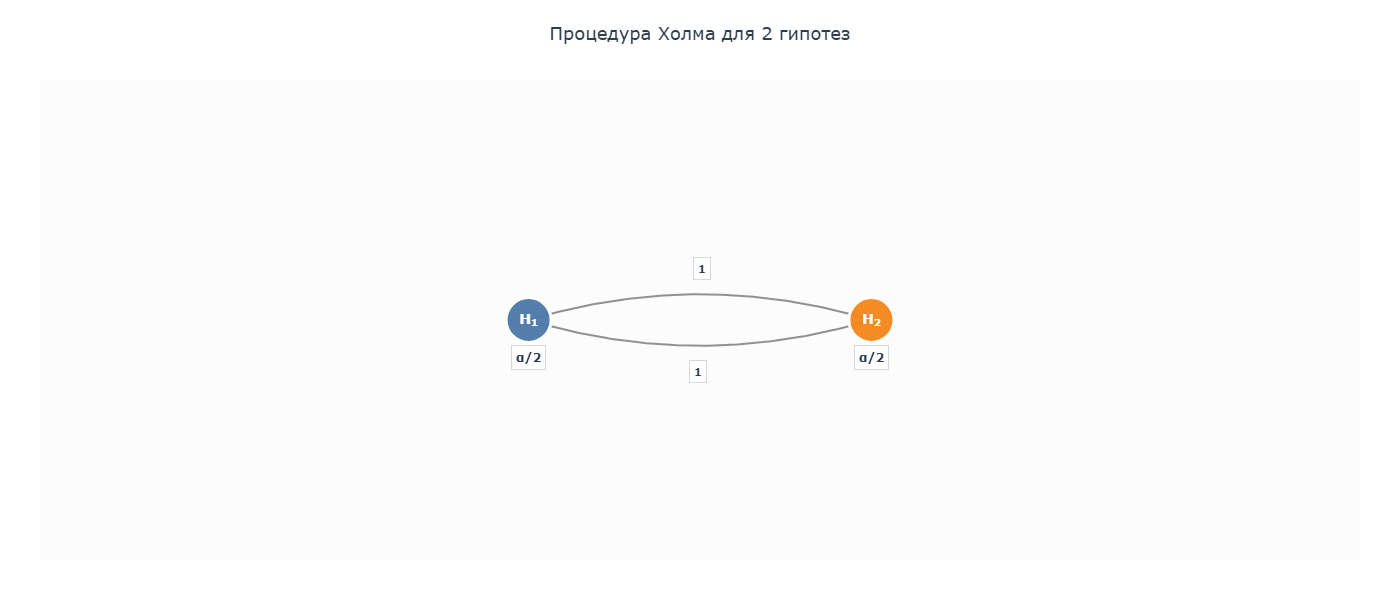

**Начальный вектор весов:** $\boldsymbol{\alpha} = (\alpha/2,\, \alpha/2)$ — бюджет разделён поровну.  
**Матрица переходов:**

$$
\mathbf{G} = \begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}.
$$


**Интерпретация:**

Если отвергнута $H_1$, её уровень $\alpha/2$ полностью переходит к $H_2$ (ребро с весом 1), так что теперь $H_2$ будет проверяться на уровне $\alpha/2 + \alpha/2 = \alpha$. Если же первой будет отвергнута $H_2$, её уровень аналогично передаётся $H_1$. Таким образом, граф из двух вершин с симметричными рёбрами полностью кодирует процедуру Холма для $m = 2$. Как мы увидим далее, обобщение на $m$ гипотез потребует полносвязного графа с равными весами $g_{ij} = 1/(m-1)$, и это будет в точности процедура Холма.

### 2.2 Алгоритм последовательного тестирования

Итак, у нас есть граф, заданный начальным вектором весов $\boldsymbol{\alpha}$ и матрицей переходов $\mathbf{G}$. Теперь мы должны формально определить, как именно с его помощью проверять гипотезы. Следующий алгоритм описывает простую итеративную процедуру, которая шаг за шагом отвергает гипотезы и обновляет граф.

---

**Входные данные**

- Множество элементарных нулевых гипотез $H_1,\dots,H_m$.
- Наблюдаемые p‑значения $p_1,\dots,p_m$.
- Общий уровень значимости $\alpha \in (0,1)$.
- Начальное распределение $\boldsymbol{\alpha} = (\alpha_1,\dots,\alpha_m)$.
- Матрица переходов $\mathbf{G} = (g_{ij})$.

---

**Алгоритм**

1. **Инициализация**  
   1.1 Положим $I = \{1,\dots,m\}$ – множество индексов ещё не отвергнутых гипотез.

2. **Выбор гипотезы для проверки**  
   2.1. Вычислим для всех $i \in I$ величину $p_i / \alpha_i$.  
   2.2. Выберем индекс $j \in I$, для которого это отношение минимально
   $$
   j = \arg\min_{i \in I} \frac{p_i}{\alpha_i}
   $$

3. **Проверка и остановка**  
   3.1. Если $p_j \le \alpha_j$, то **отвергаем** $H_j$.  
   3.2. Иначе – **останавливаем всю процедуру**: оставшиеся гипотезы не отвергаются.

4. **Обновление графа после отвержения**  
   После того как $H_j$ отвергнута, мы удаляем соответствующую вершину и перераспределяем её уровень $\alpha_j$ между оставшимися гипотезами. Формально:

   - Удаляем индекс $j$ из множества $I$:  $I \leftarrow I \setminus \{j\}$.

   - Обновляем уровни значимости оставшихся гипотез:   
   $$
   \alpha_\ell \leftarrow \alpha_\ell + \alpha_j \cdot g_{j\ell}, \qquad \ell \in I \\
   \alpha_\ell \leftarrow 0 , \qquad \ell \notin I
   $$

   - Обновляем матрицу переходов:  
   $$
   g_{\ell k} \leftarrow \frac{g_{\ell k} + g_{\ell j} \cdot g_{jk}}{1 - g_{\ell j} \cdot g_{j\ell}}, \qquad \ell,k \in I,\ \ell \neq k \\
   g_{\ell k} \leftarrow 0, \qquad \ell,k \notin I,\ \ell \neq k
   $$

5. **Повторение**  
   Если после обновления в $I$ ещё остались гипотезы ($|I| \ge 1$), возвращаемся к шагу 2, иначе завершаем процедуру.

ㅤ

**Свойства алгоритма**

1. **Строгий контроль FWER.**  
   Процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает $\alpha$ при любых конфигурациях истинных и ложных нулевых гипотез. Доказательство опирается на связь с замкнутой процедурой тестирования – мы обсудим это в разделе 2.3.

2. **Сокращённая процедура (shortcut).**  
   Алгоритм делает не более $m$ шагов и не требует явного перебора всех $2^m-1$ пересечений гипотез. Это чрезвычайно важно для практики.

3. **Независимость от порядка.**  
   Если на шаге 2 сразу несколько гипотез удовлетворяют условию $p_i \le \alpha_i$, окончательное множество отвергнутых гипотез не зависит от того, в каком порядке мы их отвергаем. Выбор «минимального отношения» – лишь удобный способ определить очерёдность.


ㅤ

**Простая иллюстрация: Холм для $m=2$**

Рассмотрим граф с $\boldsymbol{\alpha} = (\alpha/2, \alpha/2)$ и $g_{12}=g_{21}=1$. Пусть $p_1 < p_2$, и $p_1 \le \alpha/2$.

1. $p_1/\alpha_1 = \frac{p_1}{\alpha/2}$ минимально. Отвергаем $H_1$.
2. Удаляем вершину $H_1$. Уровень $\alpha/2$ полностью переходит к $H_2$:  
   $\alpha_2 \leftarrow \alpha/2 + (\alpha/2) \cdot 1 = \alpha$.
3. Теперь проверяем $H_2$: $p_2 \le \alpha$. Если да – отвергаем $H_2$, иначе – нет.

Это в точности процедура Холма: сначала проверяем более значимую гипотезу на уровне $\alpha/2$, затем оставшуюся – на полном $\alpha$.

In [ ]:
# Пример использования
alpha = 0.05
m = 2

# Начальные веса: поровну
alpha_vec = np.array([alpha/m, alpha/m])

# Матрица переходов: полносвязный граф с равными весами
g_weight = 1.0 / (m - 1)
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.055])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [ ]:
graph.draw_initial_graph(title=f"Визуализация процедуры Холма для m={m} гипотез", width=1400, height=390,
                         show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

In [ ]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=280,
                        show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

### 2.3 Связь с замкнутой процедурой тестирования

Ранее мы реализовали алгоритм, который шаг за шагом отвергает гипотезы и перераспределяет уровни значимости. Теперь мы строго докажем, что этот алгоритм контролирует групповую вероятность ошибки (FWER) на заданном уровне $\alpha$. Для этого мы погрузимся в конструкцию замкнутой процедуры тестирования (closed testing procedure) и покажем, что графический подход является её эффективной реализацией.

#### 2.3.1 Замкнутая процедура тестирования

Рассмотрим множество элементарных нулевых гипотез $H_1, H_2, \ldots, H_m$. Для любого непустого подмножества индексов $I \subseteq \{1,\ldots,m\}$ определим **пересечение гипотез** $H_I = \bigcap_{i \in I} H_i$, которое утверждает, что все $H_i$ с $i \in I$ верны одновременно. Замкнутая процедура тестирования (Marcus et al., 1976) состоит из двух правил:

1. Для каждого $I \subseteq \{1,\ldots,m\}$ выбирается **локальный тест** уровня $\alpha$, который проверяет $H_I$. Локальный тест может отвергнуть $H_I$ или нет.
2. Элементарная гипотеза $H_i$ отвергается **тогда и только тогда**, когда для **всех** $I$, содержащих $i$, локальный тест отвергает $H_I$.

Процедура гарантирует сильный контроль FWER на уровне $\alpha$ при любых зависимостях между $p$-значениями, если каждый локальный тест корректен (т.е. вероятность ошибочно отвергнуть истинное пересечение не превышает $\alpha$). Доказательство чрезвычайно просто и изящно.

ㅤ

**Теорема (контроль FWER замкнутой процедурой).**  
Пусть $T \subseteq \{1,\ldots,m\}$ — множество индексов истинных нулевых гипотез. Тогда FWER — это вероятность отвергнуть хотя бы одну $H_i$ с $i \in T$.

По построению, чтобы отвергнуть такую $H_i$, необходимо отвергнуть пересечение $H_T$ (так как $T$ содержит $i$, и условие требует отвержения всех пересечений, содержащих $i$). Следовательно, $\text{FWER} \le P$(локальный тест отвергает $H_T).$ Но $H_T$ — истинное пересечение (все гипотезы в $T$ верны), поэтому вероятность его ошибочного отвержения не превышает $\alpha$ по определению локального теста. Отсюда $\text{FWER} \le \alpha$.

В качестве примера рассмотрим случай с 4 гипотезами. Предположим, что подчеркнутые гипотезы были отклонены локальными тестами.


$$
\underline{H_{1234}} \\
\underline{H_{123}} ㅤ \underline{H_{124}} ㅤ \underline{H_{134}} ㅤ \underline{H_{234}} \\
\underline{H_{12}} ㅤ \underline{H_{13}} ㅤ \underline{H_{14}} ㅤ \underline{H_{23}} ㅤ H_{24} ㅤ H_{34} \\
\underline{H_1} ㅤ \underline{H_2} ㅤ H_3 ㅤ H_4
$$

* Здесь $H_1$ и $H_{23}$ отклонены закрытой процедурой тестирования.
* $H_2$ не отклоняется в ходе закрытого тестирования, так как $H_{24}$ не отклоняется в ходе локального тестирования.

ㅤ

К сожалению, наивная реализация требует провести $2^m - 1$ локальных тестов — уже при $m = 10$ это 1023 теста. Чтобы сделать процедуру практически применимой, необходимо строить локальные тесты специального вида, допускающие **сокращённую процедуру (shortcut)**, которая эквивалентна полному замкнутому тесту, но выполняет не более $m$ шагов.

#### 2.3.2 Взвешенный тест Бонферрони как локальный тест

В графическом подходе для каждого $I \subseteq M$ используется взвешенный тест Бонферрони. Для $I$ задаются неотрицательные веса $w_i(I)$, $i \in I$, такие что $\sum_{i \in I} w_i(I) \le 1$. Тогда пересечение $H_I$ отвергается, если существует $i \in I$, для которого $p_i \le w_i(I) \cdot \alpha$. Такой тест имеет уровень $\alpha$ благодаря неравенству Бонферрони:

$$
P_{H_I}\left( \bigcup_{i \in I} \{ p_i \le w_i(I)\alpha \} \right) \le \sum_{i \in I} P_{H_I}(p_i \le w_i(I)\alpha) \le \sum_{i \in I} w_i(I)\alpha \le \alpha.
$$

Таким образом, локальный тест корректен для любого $I$.

ㅤ

**Построение весов из графа**

Начальный граф $(\alpha, G)$ неявно задаёт семейство весов $\{w_i(I)\}$ для всех $I \subseteq M$. Алгоритм, представленный ранее, строит эти веса последовательным удалением вершин, не входящих в $I$.

Формально, пусть $J = M \setminus I$ — множество индексов, подлежащих удалению. Начиная с исходного вектора $\alpha(M) = \alpha$ и матрицы $G(M) = G$, мы поочерёдно удаляем индексы $j \in J$, применяя правила обновления:

$$
\alpha_\ell(J) =
\begin{cases}
\alpha_\ell(I) + \alpha_j(I)\, g_{j\ell}(I), & \ell \in J, \\
0, & \text{иначе},
\end{cases}
$$

$$
g_{\ell k}(J) =
\frac{g_{\ell k}(I) + g_{\ell j}(I)\, g_{jk}(I)}{1 - g_{\ell j}(I)\, g_{j\ell}(I)}, \quad \ell,k \in J,\ \ell \neq k, \text{ где } I = J \cup \{j\}
$$

В статье доказано, что итоговые веса $\alpha_i(J)$ не зависят от порядка удаления индексов. Полагая, что $w_i(I) = \alpha_i(I)/\alpha$, по построению получаем, что $\sum_{i \in I} w_i(I) \le 1$.


#### 2.3.3 Построение shortcut-а замкнутой процедуры

**Условие монотонности**

Ключевое свойство, обеспечивающее существование shortcut, — **монотонность** весов:

$$w_i(J) \ge w_i(I) \quad \text{для всех } J \subseteq I,\ i \in J.$$

В терминах исходных $\alpha_i(I)$ это означает, что при удалении гипотез (переходе от большего пересечения к меньшему) оставшиеся гипотезы могут только увеличить свою долю уровня значимости. В той же статье строго доказано, что веса, порождённые алгоритмом, предстаавленном выше, удовлетворяют условию монотонности. Интуитивно это ясно: удаляя гипотезу, мы перераспределяем её уровень на оставшиеся, поэтому их веса не уменьшаются.

**Консонантность и сокращённая процедура**

Замкнутая процедура называется **консонантной**, если для любого пересечения $H_I$, которое отвергается локальным тестом, существует хотя бы одна элементарная гипотеза $H_i$ ($i \in I$), которая может быть отвергнута на том же уровне значимости при проверке **только этого пересечения**. Иными словами, отвержение пересечения немедленно влечёт возможность отвергнуть какую-то индивидуальную гипотезу из этого пересечения.

Формально, пусть $I \subseteq \{1,\dots,m\}$ и локальный тест отвергает $H_I$. Тогда существует $i \in I$, для которого $p_i \leq \alpha_i(I),$ где $\alpha_i(I) = w_i(I)\,\alpha$ – локальный уровень, выделенный гипотезе $H_i$ внутри пересечения $I$.

ㅤ

Замкнутая процедура с взвешенными бонферрониевскими тестами, обладающими монотонностью, является **консонантной**. Чтобы понять это, рассмотрим локальный тест для $H_I$: она будет отвергнута, если  $\min_{i\in I} \left( p_i \leq w_i(I) \cdot \alpha \right) $ ~ $\min_{i\in I} \left( \frac{p_i}{w_i(I)} \leq \alpha \right) $. Выберем индекс $j \in I$, на котором достигается минимум. Тогда $\frac{p_j}{w_j(I)} \leq \alpha \quad \Rightarrow \quad p_j \leq w_j(I)\,\alpha = \alpha_j(I).$

Следовательно, элементарная гипотеза $H_j$ может быть отвергнута при проверке одного лишь пересечения $H_I$. Таким образом, консонантность выполняется **автоматически** для любого взвешенного теста Бонферрони. Ключевым является то, что **монотонность весов** обеспечивает, что после удаления отвергнутой гипотезы оставшиеся сохранят (или увеличат) свои веса, и процедура может продолжаться без нарушения контроля FWER.

**От консонантности к сокращённой процедуре**

Представим, что мы применяем замкнутую процедуру наивно: перебираем все $I \subseteq M$ в порядке возрастания размера, проверяем, отвергается ли $H_I$ по Бонферрони, и затем формируем множество отвергнутых элементарных гипотез согласно правилу: $H_i$ отвергается, если **для всех** $I$, содержащих $i$, $H_I$ отвергнуто.

Консонантность позволяет заменить эту экспоненциальную проверку последовательным алгоритмом, работающим **только с текущим множеством ещё не отвергнутых гипотез**. Вот логика shortcut:

1. В начальный момент у нас есть всё множество $M$ и веса $w_i(M)$. Поскольку пересечение $H_M$ соответствует проверке сразу всех гипотез, его локальный тест – это обычный взвешенный Бонферрони. Отвергаем $H_j$, если $p_j \leq w_j(M)\,\alpha$.
2. Если такая $H_j$ найдена, то **консонантность гарантирует**, что для любого другого пересечения $I$, содержащего $j$, также найдётся отвержение (поскольку удаление других гипотез может только увеличить вес $j$). Следовательно, $H_j$ будет отвергнута и в полной замкнутой процедуре.
3. Мы удаляем $H_j$ из рассмотрения и переходим к множеству $M' = M \setminus \{j\}$. Для этого множества мы **заново вычисляем веса** $w_i(M')$ по тем же правилам, что и в Алгоритме A1. Монотонность гарантирует, что для всех оставшихся $i$ выполняется $w_i(M') \geq w_i(M)$. Теперь мы снова применяем взвешенный Бонферрони к $H_{M'}$ – и так до тех пор, пока на очередном шаге ни одна гипотеза не будет отвергнута.
4. Процедура останавливается, когда $\min_{i\in I} \left( p_i/\alpha_i(I) > 1 \right)$. Все гипотезы, отвергнутые на предыдущих шагах, считаются отвергнутыми.

Эта последовательная процедура, как доказано в Hommel, Bretz & Maurer (2007), **эквивалентна полной замкнутой процедуре** и, следовательно, контролирует FWER. При этом она требует не более $m$ шагов и избавляет от необходимости явно выписывать и проверять $2^m-1$ пересечений.

ㅤ

Теперь видно, что алгоритм, представленный до этого, есть не что иное, как этот shortcut:

- **Шаг 2** (выбор $j$ с минимальным $p_i/\alpha_i$) – ровно то же самое, что поиск индекса, доставляющего минимум в локальном тесте Бонферрони для текущего пересечения $H_I$.
- **Шаг 3** (проверка $p_j \leq \alpha_j$) – отвержение $H_j$ на уровне $\alpha_j(I)$, что в силу консонантности означает отвержение $H_j$ в замкнутой процедуре.
- **Шаг 4** (обновление графа) – пересчёт весов для нового множества $I \setminus \{j\}$.

Таким образом, предлагаемый алгоритм напрямую реализует замкнутую процедуру тестирования с взвешенными бонферрониевскими тестами, гарантируя строгий контроль FWER без каких-либо дополнительных предположений о структуре зависимости $p$-значений.

#### 2.3.4 Пример

Пусть
* $m = 4$
* общий уровень $\alpha = 0.05$
* $\alpha = (0.01,\; 0.02,\; 0.01,\; 0.01)$
* $p$-значения $= (0.008,\; 0.03,\; 0.009,\; 0.10)$

* Матрица переходов $G$:

$$
\mathbf{G} = \begin{pmatrix}
0 & 0.5 & 0.5 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 0 & 1\\
0 & 0 & 0 & 0
\end{pmatrix}
$$

___


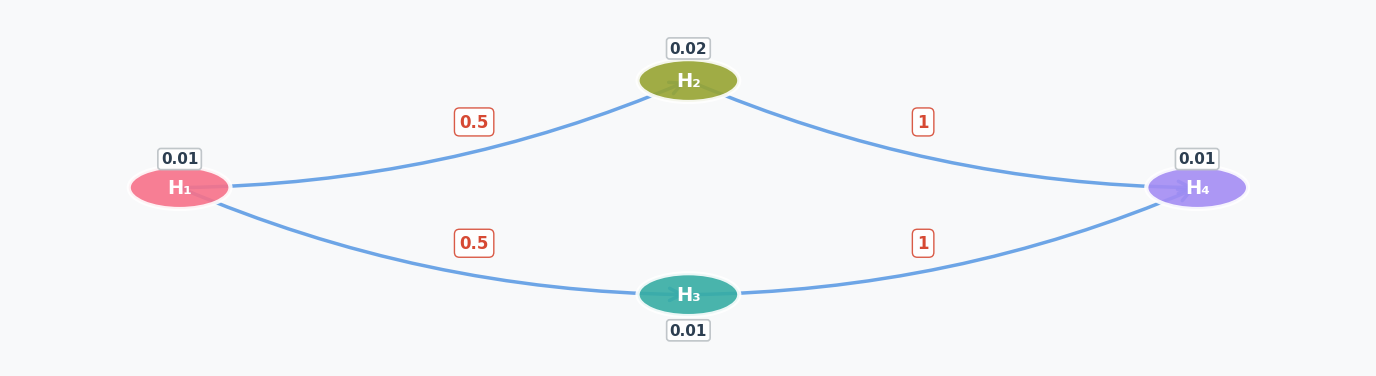

**Шаг 0. Исходное пересечение $H_{\{1,2,3,4\}}$**

* Считаем веса для $I_0 = \{1,2,3,4\}$: $w_i = \alpha_i / \alpha = (0.01/0.05,\; 0.02/0.05,\; 0.01/0.05,\; 0.01/0.05) = (0.2,\;0.4,\;0.2,\;0.2)$.

* Локальный взвешенный тест Бонферрони для $H_{I_0}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{0.008}{0.01}=0.8,\quad
  \frac{0.03}{0.02}=1.5,\quad
  \frac{0.009}{0.01}=0.9,\quad
  \frac{0.10}{0.01}=10.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_1$ минимальный коэффициент ($0.8$), и т.к. $0.8 \le 1$, то пересечение $H_{\{1,2,3,4\}}$ **отвергается**.  
* По свойству консонантности $H_1$ может быть отвергнута на уровне $\alpha_1(I_0)=0.01$, ведь $p_1 \le w_1(I_0) \cdot \alpha ㅤ(0.008 \le 0.02 \cdot 0.05)$.

**Итог шага:** отвергаем $H_1$, удаляем её из множества и идём на следующую итерацию.

**Шаг 1. Удаляем $H_1$, обновляем веса для $I_1 = \{2,3,4\}$**

Перераспределяем $\alpha_1=0.01$ согласно $G$ ($g_{12}=0.5$, $g_{13}=0.5$):
- $\alpha_2^{\text{new}} = 0.02 + 0.01\cdot 0.5 = 0.025$
- $\alpha_3^{\text{new}} = 0.01 + 0.01\cdot 0.5 = 0.015$
- $\alpha_4^{\text{new}} = 0.01$ (без изменений, т.к. из $H_1$ нет перехода в $H_4$)

ㅤ

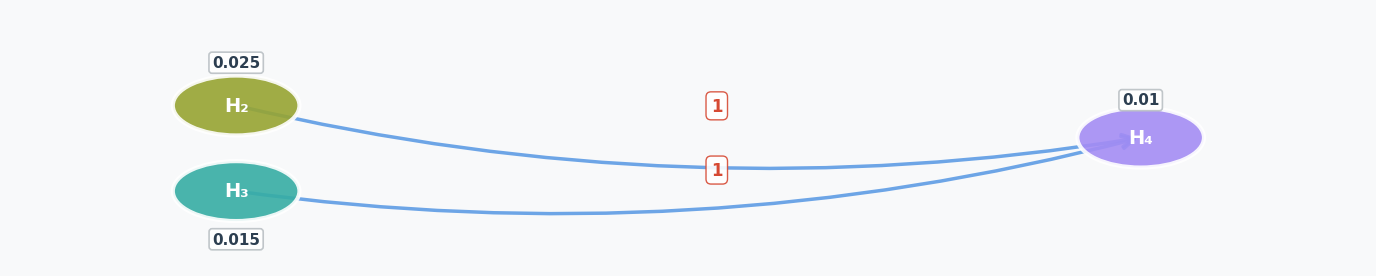

**Шаг 2. Тестируем пересечение  H{2,3,4}**

* Считаем новые веса для $I_1$: $w_i(I_1) = \alpha_i^{\text{new}} / \alpha$: $(0.025/0.05=0.5,\; 0.015/0.05=0.3,\; 0.01/0.05=0.2)$.


* Локальный взвешенный тест Бонферрони для $H_{I_1}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{p_2}{\alpha_2^{\text{new}}} = \frac{0.03}{0.025}=1.2,\quad
  \frac{p_3}{\alpha_3^{\text{new}}} = \frac{0.009}{0.015}=0.6,\quad
  \frac{p_4}{\alpha_4^{\text{new}}} = \frac{0.10}{0.01}=10.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_3$ минимальный коэффициент ($0.6$), и т.к. $0.6 \le 1$, то пересечение $H_{\{2,3,4\}}$ **отвергается**.  
* По свойству консонантности $H_3$ может быть отвергнута на уровне $\alpha_3(I_1)=0.015$, ведь $p_3 \le w_3(I_1) \cdot \alpha ㅤ(0.009 \le 0.3 \cdot 0.05)$.

**Итог шага:** отвергаем $H_3$, удаляем её из множества и идём на следующую итерацию.

**Шаг 3. Удаляем $H_3$, обновляем веса для $I_2 = \{2,4\}$**

Из $H_3$ был переход $g_{34}=1.0$, поэтому вес $H_3$ ($0.015$) целиком переходит к $H_4$:
- $\alpha_2$ остаётся $0.025$ (нет переходов из $H_3$ в $H_2$)
- $\alpha_4^{\text{new}} = 0.01$ $+ 0.015\cdot 1.0 = 0.025$

ㅤ

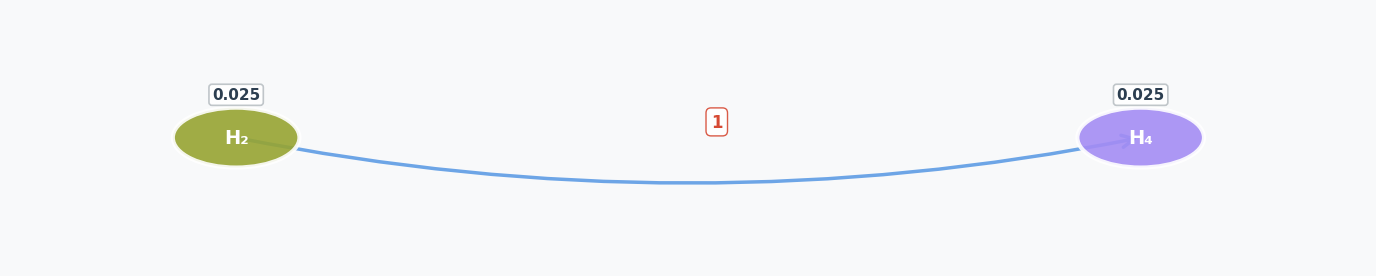

**Шаг 4. Тестируем пересечение  H{2,4}**

* Считаем новые веса для $I_2$: $w_i(I_2) = \alpha_i^{\text{new}} / \alpha$: $(0.025/0.05=0.5,\; 0.025/0.05=0.5)$.


* Локальный взвешенный тест Бонферрони для $H_{I_2}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{p_2}{\alpha_2} = \frac{0.03}{0.025}=1.2,\quad
  \frac{p_4}{\alpha_4} = \frac{0.10}{0.025}=4.0.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_2$ минимальный коэффициент ($1.2$), и т.к. $1.2 \ge 1$, то пересечение $H_{\{2,4\}}$ **не отвергается**.  

**Итог шага:** Процедура останавливается.

**Итог**

| Шаг | Рассматриваемое множество $I$ | Отвергается? | Какая $H_i$ отвергается (минимум $p_i/\alpha_i$) |
|-----|-------------------------------|--------------|------------------------------------------------|
| 0   | $\{1,2,3,4\}$                 | Да ($0.8\le1$) | $H_1$ ($p_1/\alpha_1=0.8$)                    |
| 1   | $\{2,3,4\}$                   | Да ($0.6\le1$) | $H_3$ ($p_3/\alpha_3=0.6$)                    |
| 2   | $\{2,4\}$                     | Нет ($1.2>1$) | –                                              |

**Проверка замкнутой процедурой**

Полная замкнутая процедура должна проверить все $2^4-1=15$ пересечений. Мы не делаем этого явно, но проверим, что $H_1$ и $H_3$ действительно отвергаются по правилу "отвергается, если все содержащие её пересечения отвергнуты".

- **Для $H_1$**: нужно проверить все $I$, содержащие $1$. Возьмём, например, $I=\{1,2,4\}$. Веса для такого пересечения (удаляем $H_3$) пересчитываются по тому же алгоритму. Можно показать, что для любого $I$ с $1 \in I$ локальный тест отвергает $H_I$, потому что $p_1=0.008$ очень мало и веса $w_1(I)$ только растут при удалении других гипотез (монотонность). Минимум всегда будет достигаться на $H_1$ или на другой отвергнутой гипотезе. Аналогично для $H_3$.

- **Для $H_2$**: существует пересечение $I=\{2,4\}$, которое не отвергнуто → $H_2$ не отвергается.
- **Для $H_4$**: пересечение $\{4\}$ (сама $H_4$) проверяется отдельно: при $I=\{4\}$ вес $w_4=1$, условие $p_4 \le \alpha$ не выполнено ($0.10 > 0.05$), так что $H_4$ не отвергается.

Таким образом, shortcut дал тот же результат, что и полная замкнутая процедура, но за 2 итерации вместо 15 проверок.

## 3. Детальный разбор ключевых примеров

Теперь, вооружённые полным пониманием алгоритма и его теоретической базы, перейдём к конкретным примерам. Начнём с самого простого, чтобы убедиться: классическая поправка Бонферрони – это частный случай графического подхода.

### 3.1 Пример 0: поправка Бонферрони как вырожденный граф

**Построение графа**

Пусть у нас $m$ элементарных гипотез $H_1,\dots,H_m$.
* Назначим начальные веса **поровну**: $\alpha_i = \frac{\alpha}{m}, \qquad i=1,\dots,m.$ Очевидно, $\sum_i \alpha_i = \alpha$.

* Зададим матрицу переходов $\mathbf{G}$: $g_{ij} = 0 \quad \text{для всех } i,j.$ Это означает, что из каждой вершины не исходит ни одного ребра – граф представляет собой $m$ изолированных узлов. Сумма весов исходящих рёбер равна $0 \le 1$, условие регулярности выполнено.

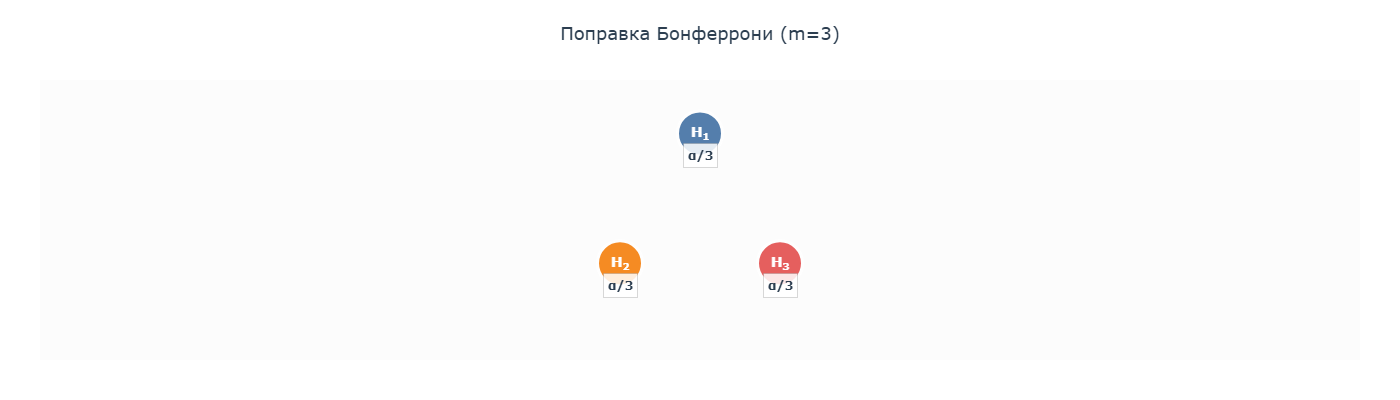

ㅤ

**Применение Алгоритма**

Запустим на таком графе Алгоритм с наблюдаемыми p‑значениями $p_1,\dots,p_m$.

1. **Инициализация:** $I = \{1,\dots,m\}$, $\alpha_i = \alpha/m$ для всех $i\in I$.
2. **Выбор гипотезы:** находим $j$ с наименьшим отношением $p_i / \alpha_i$. Поскольку все $\alpha_i$ одинаковы, это эквивалентно выбору гипотезы с **наименьшим p‑значением**.
3. **Проверка:** если $p_j \le \alpha_j = \alpha/m$, отвергаем $H_j$; иначе **стоп**.
4. **Обновление графа после отвержения $H_j$:**
   - Удаляем $j$ из $I$.
   - Для всех $\ell \in I$:
  $$
  \alpha_\ell \leftarrow \alpha_\ell + \alpha_j \cdot g_{j\ell} = \alpha_\ell + \alpha_j \cdot 0 = \alpha_\ell.
  $$
     Уровни оставшихся гипотез **не меняются**.
   - Матрица переходов остаётся нулевой.
5. **Повтор:** возвращаемся к шагу 2 с тем же набором $\alpha_i = \alpha/m$, но с уменьшенным множеством $I$. На следующей итерации снова будет выбрана гипотеза с минимальным $p$ среди оставшихся, и она будет проверена на том же уровне $\alpha/m$.

Таким образом, процедура последовательно перебирает гипотезы в порядке возрастания p‑значений и отвергает их до тех пор, пока очередное p‑значение не превысит **один и тот же порог** $\alpha/m$. Это в точности **поправка Бонферрони**: отвергаются все гипотезы с $p_i \le \alpha/m$.


При этом, в отличие от других процедур, уровень значимости не перераспределяется – каждое сравнение происходит на изначально выделенном кусочке $\alpha/m$, а освободившийся - сгорает, и именно поэтому поправка Бонферрони является самой консервативной.

In [ ]:
# Пример использования
alpha = 0.05
m = 3

# Начальные веса: поровну
alpha_vec = np.array([alpha/m, alpha/m, alpha/m])

# Матрица переходов: полносвязный граф с равными весами
g_weight = 0
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.055, 0.012])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [ ]:
graph.draw_initial_graph(title="Визуализация процедуры Бонферрони для m=3 гипотез", width=1400, height=490,
                         show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

In [ ]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=False, alpha_symbol="α", alpha_display_mode="symbolic")

### 3.2 Пример 1: процедура Холма как граф

**Построение графа**

Пусть у нас $m$ элементарных гипотез $H_1,\dots,H_m$.
* Назначим начальные веса **поровну**: $\alpha_i = \frac{\alpha}{m}, \qquad i=1,\dots,m.$ Очевидно, $\sum_i \alpha_i = \alpha$.

* Зададим матрицу переходов $\mathbf{G}$: $g_{ij} = \frac{1}{m-1}\;, g_{ii} = 0$. Сумма весов исходящих рёбер равна $\sum_{j=1}^m g_{ij} = (m-1)\cdot\frac{1}{m-1} = 1$, условие регулярности выполнено.

ㅤ

Таким образом, получается **полносвязный ориентированный граф**, в котором от каждой вершины к каждой другой идёт ребро с весом $1/(m-1)$.

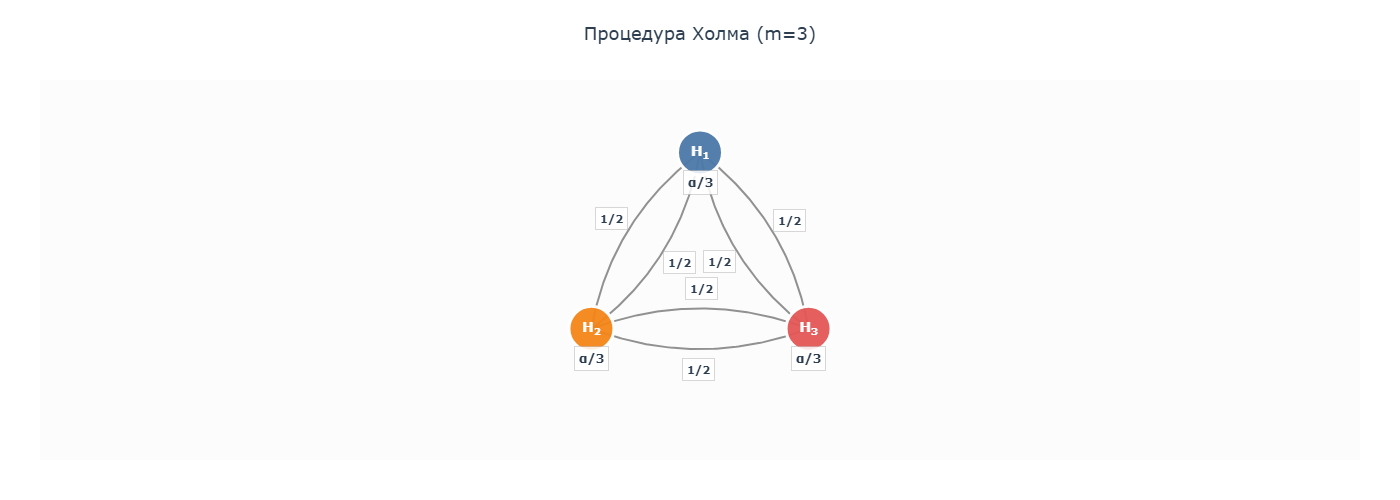

**Классическая процедура Холма**

Прежде чем запускать алгоритм, вспомним стандартную формулировку Холма:

1. Упорядочить p‑значения: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$ с соответствующими гипотезами $H_{(1)},\dots,H_{(m)}$.
2. Найти наименьший индекс $i$, для которого $p_{(i)} > \frac{\alpha}{m-i+1}$.
3. Отвергнуть все гипотезы $H_{(1)},\dots,H_{(i-1)}$.

Иными словами, самая значимая гипотеза тестируется на уровне $\alpha/m$, следующая — на $\alpha/(m-1)$, и т.д. Как только встречается гипотеза, не преодолевающая свой барьер, процедура останавливается.

ㅤ

**Работа Алгоритма на графе Холма**

Покажем, что применение Алгоритма к построенному графу даёт в точности те же результаты. Возьмём $m=3$, $\alpha=0.05$ и p‑значения $= (0.02, 0.055, 0.012)$

**Шаг 1.** Инициализация: $I = \{1,2,3\}$

  * $\alpha_i = \alpha/3 \approx 0.0167$

  * Вычисляем отношения:

  $$
  \frac{p_1}{\alpha_1} = \frac{0.02}{0.0167} \approx 1.20\qquad
  \frac{p_2}{\alpha_2} = \frac{0.055}{0.0167} \approx 3.30\qquad
  \frac{p_3}{\alpha_3} = \frac{0.012}{0.0167} \approx 0.72
  $$

  * Минимальное отношение у $H_3$: $p_3 = 0.012 \le 0.0167$ — **отвергаем и удаляем из графа $H_3$**

  * $\alpha/3$ перераспределяется поровну между $H_1$ и $H_2$ (потому что $g_{31} = g_{32} = 1/2$):

$$
\alpha_1 \leftarrow \frac{\alpha}{3} + \frac{\alpha}{3}\cdot\frac{1}{2} = \frac{\alpha}{2} = 0.025
$$
$$
\alpha_2 \leftarrow \frac{\alpha}{3} + \frac{\alpha}{3}\cdot\frac{1}{2} = \frac{\alpha}{2} = 0.025
$$

  * Пересчитывается $G$: $g_{12} = g_{21} = 1$

**Шаг 2.** Инициализация: $I = \{1,2\}$

  * $\alpha_1=\alpha_2=0.025$. Отношения:

  * Вычисляем отношения:
$$
\frac{p_1}{\alpha_1} = \frac{0.02}{0.025} = 0.8 \qquad
\frac{p_2}{\alpha_2} = \frac{0.055}{0.025} = 2.2
$$

  * Минимальное у $H_1$: $p_1 = 0.02 \le 0.025$ — **отвергаем и удаляем из графа $H_1$**.

  * $\alpha/2$ переходит к $H_2$. Получаем $\alpha_2 = 0.025 + 0.025 = 0.05$.

**Шаг 3.** Осталась одна $H_2$, проверяем: $p_2 = 0.055 > 0.05$ — **не отвергаем**.

**Итого**

Отвергнуты $H_3$ и $H_1$ — ровно те гипотезы, которые были бы отвергнуты классической процедурой Холма (на первом шаге $p_{(1)}=0.012 \le 0.05/3$, на втором $p_{(2)}=0.02 \le 0.05/2$, на третьем $p_{(3)}=0.055 > 0.05/1$).


ㅤ

**Почему граф с равными весами даёт процедуру Холма?**

Секрет кроется в том, что на каждом шаге после удаления $k$ гипотез веса оставшихся становятся одинаковыми и равными $\alpha/(m-k)$. Действительно, полносвязный граф с равными переходами $1/(m-1)$ обладает свойством «забывания»: откуда бы ни пришёл уровень значимости, он всегда равномерно распределяется между всеми оставшимися вершинами. В результате на $k$-м шаге каждая из $m-k+1$ оставшихся гипотез имеет локальный уровень $\alpha/(m-k+1)$, что в точности совпадает с порогами Холма.

In [ ]:
# Пример использования
alpha = 0.05
m = 3

# Начальные веса: поровну
alpha_vec = np.array([alpha/m, alpha/m, alpha/m])

# Матрица переходов: полносвязный граф с равными весами
g_weight = 1.0 / (m - 1)
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.055, 0.012])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [ ]:
graph.draw_initial_graph(title="Визуализация процедуры Холма для m=3 гипотез", width=1400, height=490,
                         show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

In [ ]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=False, alpha_symbol="α", alpha_display_mode="symbolic")

### 3.3 Пример 2: gatekeeping процедура для двух семейств

Теперь мы переходим к одному из наиболее важных приложений графического подхода — **гейткипингу** (gatekeeping). Этот метод незаменим, когда гипотезы естественно группируются в первичные и вторичные семейства, и вторичные разрешается проверять только после успеха первичных.

ㅤ

**Мотивация: зачем нужен гейткипинг?**

Представьте типичный A/B‑тест в продукте: вы тестируете новый алгоритм рекомендаций. У вас есть **основная метрика** — средний чек на пользователя, и несколько **охранных метрик** — CTR главной страницы, удержание через неделю, время до первого заказа. Бизнес‑логика требует:

1. Сначала доказать, что новая рекомендательная система **увеличивает** revenue по сравнению с контролем.
2. Только после этого проверить, что она **не ухудшает** охранные метрики.

Если средний чек не показал значимого прироста, мы вообще не хотим тратить статистический бюджет на проверку охранных метрик — такой вариант всё равно не пойдёт в прод. Но если метрика значимо выросла, мы готовы проверить безопасность, и здесь нам нужно иметь достаточный уровень значимости для этих вторичных тестов.

Аналогичная ситуация возникает в клинических испытаниях: первичные конечные точки (например, выживаемость) должны быть доказаны до того, как переходить к анализу вторичных (качество жизни, биомаркеры). Регуляторы требуют, чтобы FWER строго контролировался на уровне $\alpha$ для **всего** исследования, включая обе группы гипотез.

Классический гейткипинг формализует эту логику: первичное семейство $\mathcal{F}_1 = \{H_1, H_2\}$ получает весь уровень $\alpha$, а вторичное семейство $\mathcal{F}_2 = \{H_3, H_4\}$ изначально имеет нулевые уровни. Уровень переходит от первичных гипотез к вторичным **только после того, как соответствующие первичные гипотезы отвергнуты**. Более того, полный переход уровня во вторичное семейство происходит лишь при условии, что **все** гипотезы первичного семейства отвергнуты (в нашем случае — обе $H_1$ и $H_2$).

**Построение графа**

Пусть у нас $m=4$ элементарных гипотез $H_1,\dots,H_4$
* Назначим начальные веса: $\boldsymbol{\alpha} = \left( \frac{\alpha}{2},\ \frac{\alpha}{2},\ 0,\ 0 \right)$

* Зададим матрицу переходов $\mathbf{G}$:
$$
\mathbf{G} = \begin{pmatrix}
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0
\end{pmatrix}
$$

  Матрица переходов $\mathbf{G}$ отражает правило: после отвержения первичной гипотезы её уровень делится поровну между двумя вторичными. А после отвержения вторичной — полностью передаётся другой вторичной. Рёбер между первичными и от вторичных к первичным нет:

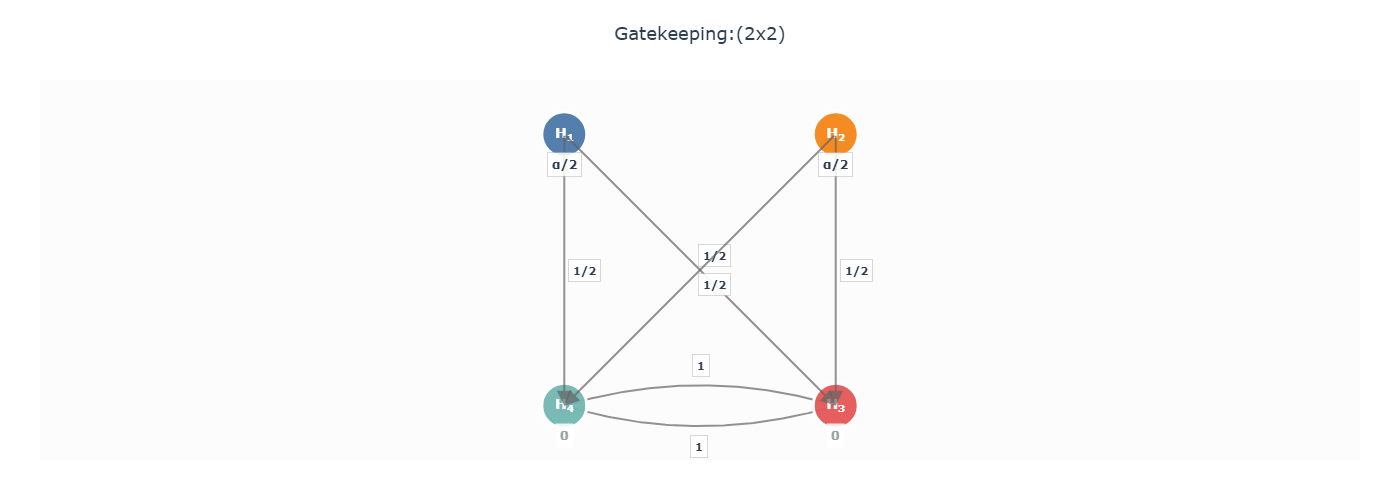

**Пример**

Пусть $\alpha=0.05$  и $p$‑значения $=(0.02,0.04,0.01,0.015)$



**Шаг 1.** Инициализация: $I = \{1,2,3,4\}$
* Локальные уровни: $\alpha_1=\alpha_2=0.025$, $\alpha_3=\alpha_4=0$  
* Сравниваем $p_i/\alpha_i$: для $H_3, H_4$ деление на ноль, поэтому они не выбираются. Выбираем минимум среди $(H_1, H_2)$:
$$
\frac{p_1}{\alpha_1} = \frac{0.02}{0.025} = 0.8 \qquad
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6
$$

* Минимальное отношение у  $H_1$. $p_1 = 0.02 \le 0.025$ — **отвергаем и удаляем из графа $H_1$**

* Уровень $\alpha_1 = \alpha/2 = 0.025$ распределяется поровну между $H_3$ и $H_4$ (веса $g_{13}=g_{14}=1/2$):

$$
\alpha_2 \leftarrow \alpha_2 = 0.025
$$
$$
\alpha_3 \leftarrow \alpha_3 + \alpha_1 \cdot g_{13} = 0 + 0.025 \cdot \frac{1}{2} = 0.0125
$$
$$
\alpha_4 \leftarrow \alpha_4 + \alpha_1 \cdot g_{14} = 0 + 0.025 \cdot \frac{1}{2} = 0.0125
$$


**Шаг 2.** Инициализация: $I = \{2,3,4\}$.  
  * Локальные уровни: $\alpha_2 = 0.025$, $\alpha_3 = 0.0125$, $\alpha_4 = 0.0125$

  * Вычисляем отношения:
$$
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6,\quad
\frac{p_3}{\alpha_3} = \frac{0.01}{0.0125} = 0.8,\quad
\frac{p_4}{\alpha_4} = \frac{0.015}{0.0125} = 1.2.
$$
  * Минимальное у $H_3$: $p_3 = 0.01 \le 0.0125$ — **отвергаем и удаляем из графа $H_3$**


* Уровень $\alpha_3 = 0.0125$ распределяется поровну между $H_4$:

$$
\alpha_2 \leftarrow \alpha_2 = 0.025 \quad
$$
$$
\alpha_4 \leftarrow \alpha_4 + \alpha_3 \cdot g_{34} = 0.0125 + 0.0125 \cdot 1 = 0.025.
$$


**Шаг 3.**   Инициализация: $I = \{2,4\}$.  

  * Локальные уровни: $\alpha_2 = 0.025$, $\alpha_4 = 0.025$
  * Вычисляем отношения:
$$
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6,\qquad
\frac{p_4}{\alpha_4} = \frac{0.015}{0.025} = 0.6.
$$
  * Минимум у $H_4$: $p_4 = 0.015 \le 0.025$ — **отвергаем и удаляем из графа $H_4$**

  * Уровень $\alpha_4 = 0.025$ **теряется**, т.к. не осталось никаких гипотез из $I $, куда бы мог перейти этот уровень.

**Шаг 4.**  Осталась только $H_2$: проверяем $p_2 = 0.04 > 0.025$ — **не отвергаем**.

**Итого**

Отвергнуты $H_1, H_3, H_4$. Гипотеза $H_2$ не отвергнута, хотя её p‑значение $0.04$ меньше $\alpha=0.05$. Уровень значимости, высвободившийся после успеха вторичных гипотез, не смог вернуться к первичной $H_2$ из‑за отсутствия обратного ребра.

ㅤ

**Улучшение с помощью ε‑рёбер**

Чтобы избежать проблемы, замеченной выше, предлагается изящное решение: добавить от вторичных гипотез обратные рёбра к первичным с **бесконечно малым весом** $\varepsilon$. Смысл в том, что пока хотя бы одна первичная гипотеза ещё не отвергнута, $\varepsilon$‑ребро практически ничего не передаёт (в пределе $\varepsilon \to 0$). Но как только **все** первичные гипотезы отвергнуты и все рёбра от них исчезают, $\varepsilon$‑ребро становится единственным исходящим, и его вес нормируется к $1$. Это позволяет уровню, накопленному во вторичном семействе, вернуться в первичное и помочь отвергнуть оставшиеся гипотезы.

Модифицированная матрица переходов $G$ тогда будет выглядеть следующим образом:

$$
\mathbf{G}_\varepsilon = \begin{pmatrix}
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 1/2 & 1/2 \\
\varepsilon & \varepsilon & 0 & 1-2\varepsilon \\
\varepsilon & \varepsilon & 1-2\varepsilon & 0
\end{pmatrix}.
$$

Теперь после отвержения $H_1, H_3, H_4$ $\varepsilon$‑ребро $H_4 \to H_2$ становится единственным путём, и **весь** уровень $0.025$ передаётся $H_2$. Тогда $\alpha_2$ становится $0.025 + 0.025 = 0.05$, и $p_2 = 0.04 \le 0.05$ — $H_2$ отвергается! В результате отвергнуты все четыре гипотезы.

#### Обычный gatekeeping

In [ ]:
# Пример использования
alpha = 0.05
m = 4

# Начальные веса:
alpha_vec = np.array([alpha/2, alpha/2, 0.0, 0.0])

# Матрица переходов:
G = np.array([[0.0, 0.0, 1/2, 1/2],
              [0.0, 0.0, 1/2, 1/2],
              [0.0, 0.0, 0.0, 1.0],
              [0.0, 0.0, 1.0, 0.0]])

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.04, 0.01, 0.015])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [ ]:
graph.draw_initial_graph(title=f"Визуализация gatekeeping для m={m} гипотез", width=1400, height=600,
                         show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

In [ ]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

#### ε‑gatekeeping

In [ ]:
# Пример использования
alpha = 0.05
m = 4
epsilon = 1e-6

# Начальные веса:
alpha_vec = np.array([alpha/2, alpha/2, 0.0, 0.0])

# Матрица переходов:
G_eps = np.array([[0.0, 0.0, 0.5, 0.5],
                  [0.0, 0.0, 0.5, 0.5],
                  [epsilon, epsilon, 0.0, 1-2*epsilon],
                  [epsilon, epsilon, 1-2*epsilon, 0.0]])

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.04, 0.01, 0.015])

graph = Graph(m, alpha, alpha_vec, p_vals, G_eps)

In [ ]:
graph.draw_initial_graph(title=f"Визуализация gatekeeping для m={m} гипотез", width=1400, height=600,
                         show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

In [ ]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=True, alpha_symbol="α", alpha_display_mode="symbolic")

## 4. Расширения графического подхода для обобщённых ошибок

### 4.1 Graphical approaches for k‑FWER control

В предыдущих разделах мы рассматривали строгий контроль FWER — вероятности хотя бы одной ложной находки. Однако в разведочных A/B‑тестах, при анализе многих вторичных метрик или в исследованиях безопасности допустимо ослабить контроль, чтобы повысить мощность. Для этого используют **обобщённые метрики ошибок**. Первая из них — **k‑FWER** (generalised familywise error rate), определяемая как

$$
k\text{-FWER} = P(V \ge k),
$$

где $V$ — число ложных отклонений, а $k \ge 1$ — заранее заданное целое число. При $k=1$ получаем обычный FWER; при $k=2$ разрешаем ровно одну ложную находку; при $k=3$ — две и т.д.

Контроль k‑FWER означает, что вероятность допустить не менее $k$ ложных отклонений не превышает $\alpha$. **Обобщенная процедура Бонферрони** позволяет контролировать k-FWER: отклонять любые $H_i$, для которых $p_i ≤ k\alpha/m$. Предполагая известные положительные веса $w_i$, которые удовлетворяют $\sum^{m}_{i= 1} w_{i} = 1$, Романо и Вольф (Romano & Wolf, 2010) представили **взвешенную обобщенную процедуру Бонферрони**: отклонить любой $H_i$, для которого $p_i ≤ w_i k\alpha$. Если $w_i = 1/m$ для всех $i$, то это эквивалентно невзвешенной версии. Чтобы расширить графический подход к управлению k-FWER, возникает соблазн просто
замените $α$ на $k\alpha$, по аналогии с модификацией, внесенной для обобщенных процедур Бонферрони. Однако, в целом, это не контролирует k-FWER для $k > 1$.

Статья Robertson et al. (2020) предлагает два способа адаптировать графический подход для контроля k‑FWER: **дополненный (augmented)** и **обобщённый (generalised)**. Мы начнём с более простого и надёжного — дополненного.

#### 4.1.1 Augmented graphical approach for k‑FWER control

Идея дополненной процедуры чрезвычайно естественна: **сначала выполнить обычный FWER‑тест, а затем, если число отвергнутых гипотез недостаточно для k‑FWER, «добрать» дополнительные отверждения**. Это не нарушает контроль k‑FWER, потому что на первом этапе мы гарантируем $P(V \ge 1) \le \alpha$, а на втором этапе мы можем добавить не более $k-1$ дополнительных отверждений, так что в худшем случае мы получим $k$ ложных отклонений с вероятностью не выше $\alpha$.

Формально алгоритм выглядит так:

1. Применить обычную Bonferroni‑based графическую процедуру для контроля FWER на уровне $\alpha$.
2. Пусть $I$ — **множество индексов оставшихся (неотвергнутых) гипотез.** Если $I$ пусто, остановиться.
3. Выполнить шаги **ii**–**iv** обычного графического алгоритма, но с заменой $\alpha$ на $\delta$, до тех пор, пока не будет сделано до $k-1$ дополнительных отверждений.


Таким образом, итоговое множество отвергнутых гипотез содержит все с первого этапа плюс ещё до $k-1$ гипотез. Процедура гарантированно отвергает **не меньше** гипотез, чем обычный FWER‑тест, и контролирует k‑FWER. Контроль k‑FWER следует из того, что FWER на первом этапе не превышает $\alpha$, а второй этап может добавить не более $k-1$ ложных отклонений (поскольку мы отвергаем не более $k-1$ гипотез дополнительно). Строгое доказательство основано на том, что множество истинных нулевых гипотез конечно, и вероятность того, что среди дополнительных отвергнутых окажется хотя бы одна истинная, всё равно ограничена.


Здесь $\delta \ge 0$ — параметр, определяющий, сколько «свободных» отверждений мы используем. На практике часто берут $\delta = 1$, что гарантирует, что все $k-1$ дополнительных гипотез будут отвергнуты (разумеется, если в $I$ осталось достаточно гипотез). Конечно, это связано с потенциальными издержками отклонения гипотез с $p$-значениями, близкими к 1, которые, скорее всего, окажутся нулевыми. И наоборот, низкие значения $δ$ означают, что мы готовы отвергнуть гипотезу только в том случае, если против нее имеются достаточно веские доказательства.

Выбор значения $δ$ также может зависеть от данных, чтобы гарантировать выполнение (до) $k-1$ дополнительных отклонений. Более конкретно, мы можем увеличить значение $δ$, чтобы выполнить одно дополнительное отклонение, затем, при необходимости, увеличивать значение $δ$, пока не будет выполнено еще одно дополнительное отклонение, и так далее.

#### 4.1.2 Generalised graphical approach for k‑FWER control

Альтернативный подход — модифицировать сами пороги внутри графического алгоритма, чтобы с самого начала допускать до $k-1$ ложных отклонений. Это **обобщённая процедура**.

Формально алгоритм выглядит так:

1. **Инициализация:** $I = M$  (множество всех гипотез).
2. **Шаг 1:** Отвергнуть любую гипотезу $H_i$, $i \in I$, для которой $p_i \le w_i(I)\, k\alpha.$
3. Пусть $R = \{i \in I : p_i \le w_i(I)\,k\alpha\}$ — множество гипотез, отвергнутых на этом шаге.  
   * Если $|R| < k$ или $|R| = |I|$, то остановиться.  
   * Иначе обновить $I \leftarrow I \setminus R$.
4. **Последующие шаги:** Для оставшихся гипотез $i \in I$ отвергнуть $H_i$, если  
   $$
   p_i \le \min_{J \subseteq R, |J| = k-1} \bigl\{ w_i(I \cup J) \bigr\}\, k\alpha,
   $$
   Тогда $R'$ — множество индексов отвергнутых на этом шаге гипотез.  
   * Обновить $R$ и $I$ соответственно:
   $$
   I \rightarrow I \setminus R' \\
   R \rightarrow R  \cup R'
   $$
5. Повторять шаг 4, пока $|I| > 1$.

Суть шага 4: среди уже отвергнутых гипотез может быть до $k-1$ истинных нулевых гипотез. Мы не знаем, какие именно, поэтому для каждой оставшейся гипотезы мы рассматриваем все возможные подмножества $J$ размера $k-1$ среди отвергнутых, которые могли бы быть истинными. Для каждого такого $J$ мы вычисляем вес $w_i(I \cup J)$ — то есть вес гипотезы $H_i$ в расширенном множестве, куда возвращены эти $k-1$ гипотез. Минимальный из этих весов даёт наиболее консервативный порог, гарантирующий контроль k‑FWER.

ㅤ

Но у обобщённой процедуры есть существенный недостаток: **проблема доноров.** Рассмотрим гипотезу $H_j$, у которой **менее $k$ доноров** (т.е. менее $k$ других гипотез, из которых есть рёбра в $H_j$). Если начальный вес $H_j$ равен нулю, то даже после отвержения всех её доноров её вес останется нулевым, потому что перераспределение уровня не может превысить сумму входящих весов. В результате такая гипотеза **никогда не будет отвергнута**, даже если её $p$‑значение очень мало. В иерархических графах (gatekeeping, фиксированная последовательность) многие гипотезы имеют ровно одного или двух доноров, поэтому обобщённая процедура может отвергнуть даже меньше гипотез, чем обычный FWER‑тест, что противоречит цели повышения мощности.

#### 4.1.3 Existing power comparisons

В статье проведены численные эксперименты на реальных данных, сравнивающие дополненную и обобщённую процедуры для контроля k‑FWER. Основной вывод: **дополненная процедура, как правило, мощнее и надёжнее**, особенно при наличии иерархической структуры.

Рассмотрим фармакодинамическое исследование Ferber et al. (2011),там 15 гипотез образуют сложный граф с начальными весами 1/3 у трёх гипотез и нулями у остальных:

* При $k=1$ обе процедуры эквивалентны и отвергают 8 гипотез.
* При $k=2$: дополненная — 9 отвержений, обобщённая — только 3.
* При $k=3$: дополненная — 10 отвержений, обобщённая — 3.

Обобщённая процедура «застревает» на трёх гипотезах с ненулевыми начальными весами, потому что остальные гипотезы имеют менее \(k\) доноров и не могут повысить свой вес.

Даже если всем гипотезам дать равные начальные веса (1/15), обобщённая процедура начинает работать лучше, но всё равно уступает дополненной при \(k \ge 3\). Это связано с тем, что дополненная процедура на втором этапе с \(\delta=1\) без труда «добирает» нужное число отверждений, используя уже перераспределённые уровни, и не страдает от проблемы доноров.

Таким образом, **практическая рекомендация**: в задачах с иерархической структурой гипотез (которые типичны для A/B‑тестов и клинических исследований) предпочтительно использовать дополненную процедуру. Обобщённая процедура может рассматриваться только для полносвязных графов типа Холма, где все гипотезы равноправны.

### 4.2 Graphical approaches for FDP and (asymptotic) FDR control

Контроль k‑FWER, который мы только что изучили, позволяет ограничить **число** ложных отклонений. Но в исследовательских задачах с большим числом гипотез часто важнее контролировать не абсолютное число, а **долю** ложных находок среди всех сделанных утверждений. Представьте, что в масштабном A/B‑тесте вы проверили 200 метрик и отвергли 50 из них. Если вы использовали контроль 5‑FWER, вы можете быть уверены, что ложных среди 50 не более 4. Но если вы не знаете, сколько всего будет отвергнуто, абсолютная цифра даёт мало информации. Гораздо удобнее сказать: «с вероятностью 95% доля ложных отклонений не превышает 10%». Именно это даёт контроль **хвостовой вероятности FDP** (False Discovery Proportion).

Формально, пусть $V$ — число ложных отклонений, $R$ — общее число отвергнутых гипотез. Тогда

$$
\mathrm{FDP} = \frac{V}{\max(R,1)} .
$$

Мы хотим гарантировать, что

$$
P(\mathrm{FDP} > \gamma) \le \alpha,
$$

где $\gamma \in [0,1)$ — максимально допустимая доля ложных находок. При $\gamma=0$ мы возвращаемся к обычному FWER.

С контролем FDP тесно связан **False Discovery Rate** (FDR) — математическое ожидание FDP. Хотя мы не будем углубляться в детали, важно отметить, что процедуры, контролирующие FDP на уровне $\alpha$, автоматически обеспечивают **асимптотический контроль FDR** на уровне $\alpha^* = \alpha(1-\gamma)+\gamma$ (Lehmann & Romano, 2005) или даже $2\alpha$ (van der Laan et al., 2004). Таким образом, графические методы для FDP дают нам и контроль FDR «в придачу».

Статья предлагает два способа контролировать FDP в рамках графического подхода: дополненный и обобщённый. Их логика полностью аналогична случаю k‑FWER, только вместо числа дополнительных отверждений управляют долей.

#### 4.2.1 Augmented graphical approach for FDP control

Дополненная процедура для FDP является прямым обобщением дополненной процедуры для k‑FWER. Вместо того чтобы добавлять ровно $k-1$ отверждений, мы добавляем до $D$ дополнительных, где $D$ — наибольшее целое число, удовлетворяющее неравенству

$$
\frac{D}{D + |R|} \le \gamma,
$$

и $R$ — множество гипотез, отвергнутых на первом этапе (обычный FWER‑тест). Это гарантирует, что итоговая доля дополнительных отверждений не превысит $\gamma$.

Формально алгоритм выглядит так:

1. Применить обычную Bonferroni‑based графическую FWER‑процедуру на уровне $\alpha$. Получить множество отвергнутых гипотез $R$.
2. Пусть $I$ — множество оставшихся (неотвергнутых) гипотез. Если $I$ пусто, остановиться.
3. Вычислить $D$ — наибольшее целое, для которого $\frac{D}{D+|R|} \le \gamma$. Если $D=0$, остановиться.
4. Выполнить шаги **ii**-**iv** обычного графического алгоритма, заменив $\alpha$ на $\delta$, до тех пор, пока не будет сделано **до $D$ дополнительных отверждений**.


После выполнения этого алгоритма итоговое множество отвергнутых гипотез содержит все $R$ с первого этапа плюс до $D$ дополнительных. Вероятность того, что доля ложных среди них превысит $\gamma$, не больше $\alpha$.

Если положить $\gamma = (k-1)/(k-1+|R|)$, дополненная FDP‑процедура сведётся к дополненной k‑FWER процедуре с параметром $k$. Таким образом, FDP‑версия является более гибкой: она автоматически адаптирует число дополнительных отверждений к числу уже сделанных, не требуя фиксировать $k$ заранее.

#### 4.2.2 Generalised graphical approach for asymptotic FDP control

Обобщённая процедура для FDP строится на базе обобщённой процедуры для k‑FWER. Идея состоит в том, чтобы последовательно применять процедуру $k_j$-FWER для $k_j = 1, 2, 3, \dots$ до тех пор, пока не выполнится условие, гарантирующее контроль FDP.

Тогда алгоритм будем следующим:

1. Положим $j=1$, $k_1=1$.
2. Применить обобщённую $k_j$-FWER процедуру и получить множество отвергнутых гипотез $R_j$.
3. Если $|R_j| < k_j / \gamma - 1$, остановиться и отвергнуть все гипотезы, отвергнутые $k_j$-FWER процедурой.
4. Иначе положить $j \leftarrow j+1$, $k_j = k_{j-1}+1$ и вернуться к шагу 2.

Другими словами, мы начинаем с обычного FWER. Если это даёт «слишком много» отвергнутых гипотез относительно порога $1/\gamma - 1$, мы переходим к $k=2$, потом к $k=3$ и так далее, пока число отвергнутых не станет достаточно малым. На каждом шаге используется обобщённая процедура для соответствующего $k$.

Данный алгоритм доказанно обеспечивает **асимптотический контроль FDP** (Roman & Wolf, 2010). Однако он наследует все недостатки обобщённой k‑FWER процедуры, включая проблему доноров. На практике, особенно в иерархических графах, он часто останавливается уже при $k=1$ или $k=2$, отвергая очень мало гипотез, в то время как дополненная процедура продолжает набирать полезные находки.

#### 4.2.3 Existing power comparisons

В той же статье сравниваются дополненная и обобщённая процедуры для FDP на том же фармакодинамическом исследовании Ferber et al. (2011). Результаты полностью согласуются с выводами для k‑FWER.

При $\gamma = 0.1$ обе процедуры дают одинаковые 8 отвержений (это соответствует $k=1$, так как $D$ оказывается равным 0). При $\gamma = 0.2$ дополненная процедура отвергает 10 гипотез, обобщённая — только 3. При $\gamma = 0.3$ разрыв ещё больше: 11 против 3. Причина та же — обобщённая процедура «застревает» из‑за нехватки доноров, в то время как дополненная спокойно добавляет отверждения, уважая перераспределённые после первого этапа уровни.

Таким образом, **практическая рекомендация** остаётся прежней: в реальных задачах с иерархической структурой гипотез используйте дополненную процедуру для контроля FDP. Она проще, надёжнее и обеспечивает лучшую мощность.

## 5. Методологические расширения графического подхода

До сих пор мы рассматривали классический графический подход, основанный на взвешенных тестах Бонферрони и однократном анализе данных в конце эксперимента. Однако реальные клинические и A/B‑исследования часто требуют более сложных дизайнов: промежуточных анализов, сложных логических условий (например, «хотя бы K из N»), или учёта корреляции между тестовыми статистиками. В этом разделе мы познакомимся с тремя важными расширениями, которые делают графический подход ещё более универсальным инструментом.

### 5.1 Entangled graphs

**Мотивация.** Обычный граф отлично представляет иерархические и последовательные стратегии. Но что делать, если логика требует выполнения условия типа «отвергнуть хотя бы 6 из 9 первичных гипотез, прежде чем перейти к вторичным»? Такой **гейткипинг «K из N»** невозможно изобразить одним графом, потому что веса должны зависеть от того, **какие именно** из первичных гипотез отвергнуты, а не только от их числа.

**Решение.** Маурер и Бретц (Maurer & Bretz, 2013a) предложили концепцию **запутанных графов** (entangled graphs). Идея состоит в том, чтобы построить отдельный обычный граф для каждого возможного подмножества первичных гипотез, удовлетворяющего условию (например, для каждой комбинации из 6 успешных первичных конечных точек). Затем все эти графы «запутываются» (entangle) с весами, пропорциональными вероятности или важности каждой комбинации. Формально, если имеется $L$ сценариев, каждому соответствует граф $\mathcal{G}_l$ с весом $c_l$ $(\sum c_l = 1$). При тестировании на каждом шагу уровень значимости перераспределяется **одновременно** по всем графам, взвешиваясь с коэффициентами $c_l$. Когда в каком‑то графе достигается полное отвержение нужного семейства, его вес может переключаться на следующий этап.

**Значение.** Запутанные графы позволяют реализовать любые линейные логические условия в рамках замкнутой процедуры тестирования, сохраняя строгий контроль FWER. Это критически важно для сложных клинических протоколов, где успех определяется несколькими взаимозаменяемыми конечными точками.

### 5.2 Group sequential designs

**Мотивация.** В клинических испытаниях (а иногда и в некоторых A/B‑тестах) данные поступают последовательно, и этически необходимо проводить **промежуточные анализы** (interim analyses) с возможностью досрочной остановки при очевидной эффективности или бесполезности. Каждый такой анализ «тратит» часть общего уровня значимости $\alpha$, и эту трату необходимо планировать заранее с помощью **функции траты $α$** ($α$‑spending function), например, границ O’Brien–Fleming или Pocock.

**Решение.** Маурер и Бретц (Maurer & Bretz, 2013b) обобщили графический подход на групповые последовательные дизайны. Основная идея: на каждом промежуточном анализе $t$ для каждого пересечения гипотез $H_I$ вычисляются **номинальные уровни значимости** $\tilde{\alpha}_{i,t}(\kappa_I)$, где $\kappa_I$ — общий уровень, выделенный на это пересечение. Эти номинальные уровни зависят от выбранной функции траты $α$ и от информации, накопленной к моменту $t$. Затем применяется графический алгоритм, который на каждом шаге использует эти номинальные уровни вместо обычных бонферрониевских порогов.

Ключевое условие — **монотонность номинальных уровней** по отношению к общему уровню $\kappa$: $\tilde{\alpha}_{i,t}(\kappa') \ge \tilde{\alpha}_{i,t}(\kappa)$ при $\kappa' > \kappa$. Это выполняется для большинства стандартных функций траты. При соблюдении монотонности весь аппарат замкнутого тестирования и консонантности сохраняется, и можно построить shortcut‑процедуру.

**Значение.** Графический подход с групповым последовательным дизайном позволяет контролировать FWER (или k‑FWER, FDP) во времени, принимая решения об остановке или продолжении на каждом промежуточном анализе. Это делает его мощным инструментом для планирования и мониторинга клинических испытаний.

### 5.3 Weighted parametric tests

**Мотивация.** Все рассмотренные нами процедуры использовали **взвешенный тест Бонферрони** в качестве локального теста для каждого пересечения гипотез. Бонферрони корректен при **любых** зависимостях между $p$‑значениями, но за это приходится платить консервативностью: реальный уровень отвержения часто существенно ниже номинального $\alpha$, особенно при сильной положительной корреляции между тестовыми статистиками. В A/B‑тестах, где метрики часто сильно скоррелированы (например, различные показатели вовлечённости), это приводит к потере мощности.

**Решение.** Если совместное распределение тестовых статистик известно (например, многомерное нормальное), можно заменить взвешенный Бонферрони на **взвешенный min‑p тест** (Westfall & Young, 1993; Westfall et al., 1998). Для пересечения $H_I$ с весами $w_i(I)$ этот тест отвергает $H_I$, если существует $i \in I$ такое, что

$$
p_i \le c_I \cdot w_i(I)\,\alpha,
$$

где константа $c_I \ge 1$ подбирается так, чтобы

$$
P_{H_I}\left( \bigcup_{i \in I} \{p_i \le c_I \, w_i(I)\,\alpha\} \right) \le \alpha.
$$

Благодаря учёту корреляций, $c_I$ может быть значительно больше 1, что повышает мощность.

Для того чтобы такой параметрический тест можно было встроить в графический shortcut, необходимо, чтобы выполнялось **условие монотонности** с поправкой на $c_I$:

$$
c_{J}\, w_i(J) \ge c_{I}\, w_i(I) \quad \text{для всех } J \subseteq I,\; i \in J.
$$

Это условие может нарушаться для произвольных графов, но Bretz et al. (2011) и Xi et al. (2017) показали, как модифицировать веса или использовать консервативные верхние границы для $c_I$, чтобы его обеспечить. На практике для многих стандартных графов (Холм, gatekeeping) условие выполняется автоматически.

**Значение.** Использование параметрических тестов в графическом подходе позволяет существенно повысить мощность при сильной корреляции метрик, что типично для онлайн‑экспериментов. Однако это требует осторожной верификации монотонности и, возможно, модификации весов. В стандартных пакетах (например, gMCP в R) поддержка параметрических тестов уже реализована.

## 6. Примеры применения графических процедур

В этой части лекции мы посмотрим применение изученных графических методов к трём реальным клиническим исследованиям. Каждый кейс иллюстрирует различные аспекты: иерархические семейства гипотез, гейткипинг «K из N», сравнение дополненных и обобщённых процедур.


### 6.1. Pharmacodynamic study

**Контекст исследования**

Это разведочное (exploratory) клиническое исследование фармакодинамики нового препарата, воздействующего на GABA‑A рецепторы в головном мозге. Эффект измерялся с помощью количественной электроэнцефалографии (qEEG). Три дозы препарата (0.25 мг, 0.5 мг и 1 мг) сравнивались с плацебо. Запись qEEG в течение первых 15 минут после введения была разбита на пять временны́х интервалов по 3 минуты. Таким образом, каждый контраст «доза‑время» образовывал отдельную нулевую гипотезу:  

$H_{ij}:$ изменение от исходного уровня под дозой $j$ $(j=1,2,3$) во временно́м интервале $i$ ($i=1,\dots,5$) не отличается от плацебо. Всего $3 \times 5 = 15$ элементарных гипотез.

Исходные $p$‑значения, полученные из линейной модели смешанных эффектов, приведены в Таблице 1.

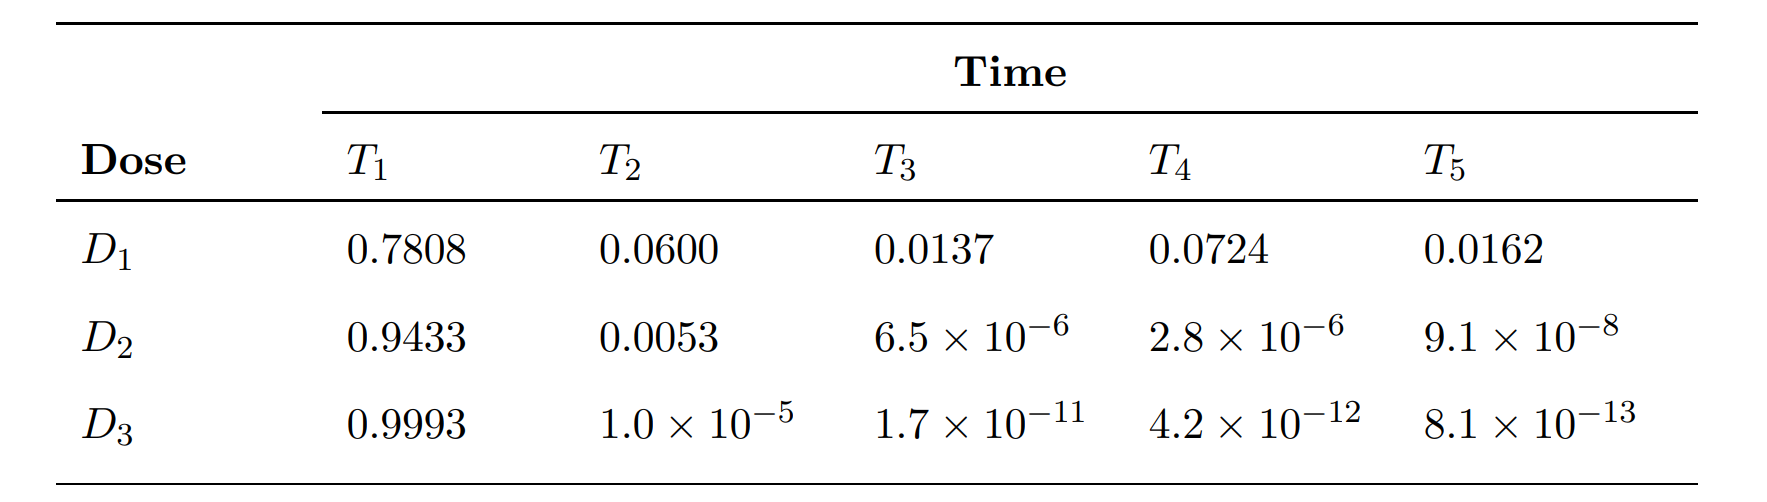

<small>**Таблица 1.** $p$‑значения для 15 контрастов «доза × время» в фармакодинамическом исследовании Ferber et al. (2011).</small>

Видна сильная значимость высоких доз в поздние временны́е точки (T3–T5) и почти полное отсутствие эффекта на ранних этапах.

**Иерархическая стратегия тестирования**

Исследователи определили естественный порядок проверки: от более высоких доз и более поздних временны́х точек к более низким дозам и ранним точкам, отражая ожидаемую силу эффекта. Визуально эта стратегия представлена направленным графом на Рис. 3.

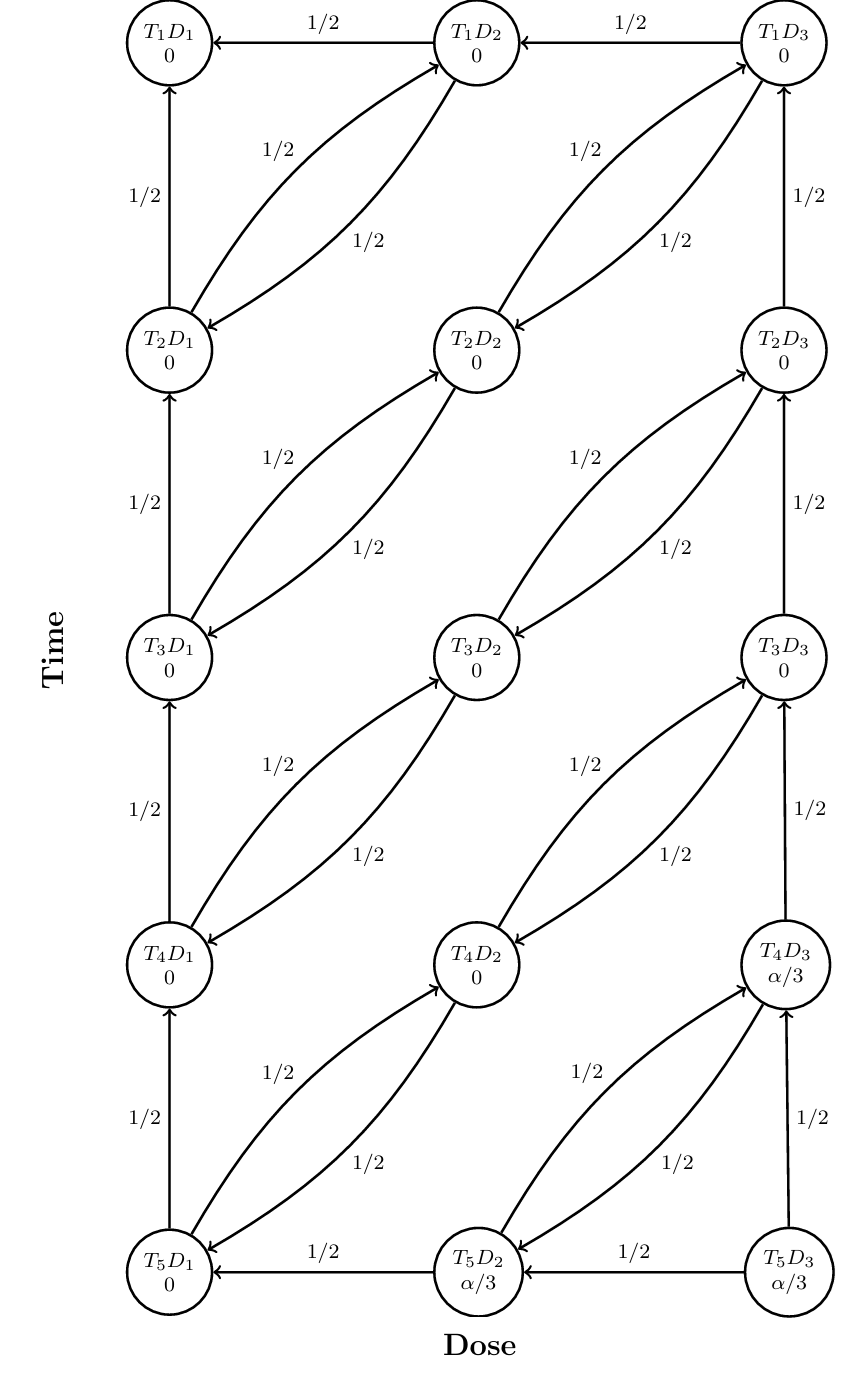

<small>**Рис. 3** «Graph representing the testing strategy for the pharmacodynamic study described in Ferber et al. (2011), with modified initial weights».</small>

Граф имеет 15 вершин $T_iD_j$. Стрелки направлены от более значимых контрастов к менее значимым. В оригинальной публикации Ferber et al. (2011) многие вершины имели нулевые начальные веса (вся $α$ была сосредоточена на $T_5D_3$), однако для обобщённых процедур (generalised) такая конфигурация приводит к проблеме доноров, потому что у них недостаточно входящих рёбер. Поэтому в статье были рассмотрены **два варианта начальных весов**:

1. **Модифицированные веса (modified weights):** трём конечным гипотезам — $T_4D_3$, $T_5D_2$, $T_5D_3$ — присвоен вес $1/3$, остальным 12 гипотезам — 0. Это отражено на Рис. 3 и используется в большей части анализа.
2. **Равномерные веса (equal weights):** каждая из 15 гипотез получает вес $1/15$. Этот вариант служит для проверки чувствительности и демонстрации того, как начальное распределение влияет на мощность обобщённых процедур.

**Применение графических процедур**

Теперь мы применяем к этим данным все рассмотренные ранее процедуры: обычный FWER‑тест, дополненный (augmented) и обобщённый (generalised) контроль k‑FWER, а также дополненный и обобщённый контроль FDP. Для краткости мы сразу приводим сводку результатов из статьи.

|Распределение весов|Результаты|
|---|---|
|Модифицированные веса|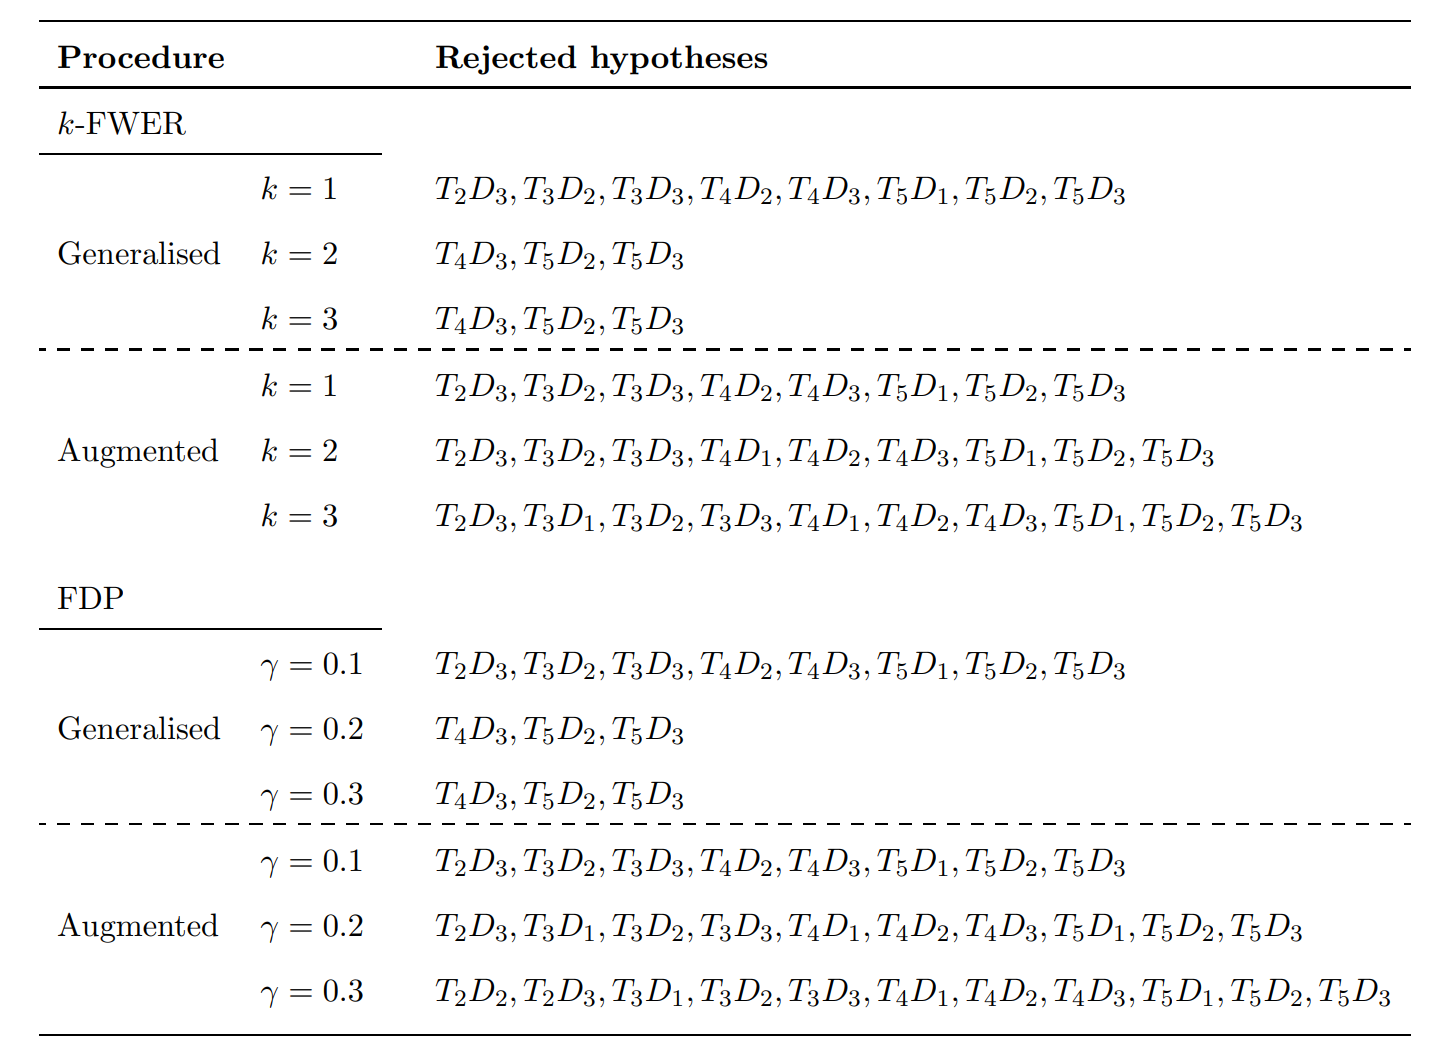 |
|Равномерные веса | 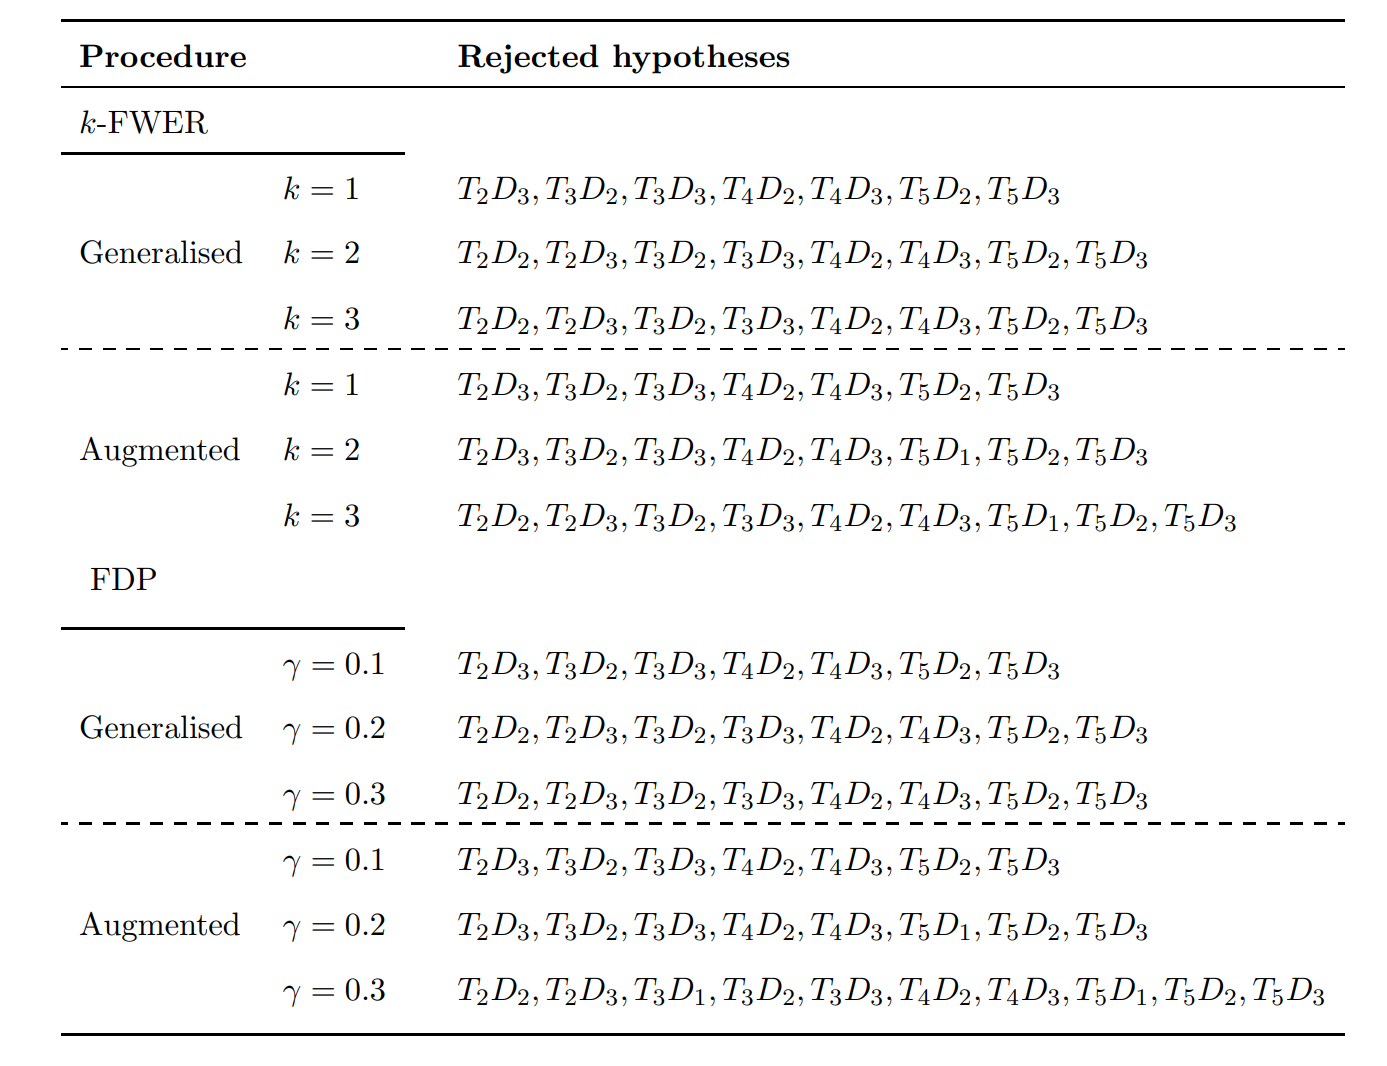 |

**Обсуждение результатов**

Сравнение таблиц позволяет сделать несколько важных наблюдений.

1. **Обычный FWER‑тест ($k=1$, $γ=0.1$):** Число отвергаемых гипотез примерно одинаково для обоих вариантов весов (7–8). Это говорит о том, что при строгом контроле ошибки I рода выбор начального распределения $α$ не слишком критичен, если граф позволяет перераспределять уровни. Заметим, что при модифицированных весах отвергается даже несколько больше гипотез, чем при равномерных, благодаря более эффективному перераспределению от трёх «центров тяжести».

2. **Поведение обобщённой процедуры:** При модифицированных весах она «ломается» уже при $k=2$ — отвергаются только три гипотезы с ненулевыми начальными весами. Причина — недостаток доноров: остальные 12 гипотез имеют менее двух входящих рёбер, и их вес никогда не возрастает, даже когда связанные гипотезы отвергнуты. При равномерных весах, где все имеют начальный уровень и больше доноров, обобщённая процедура работает лучше, но всё равно «насыщается» при $k \ge 3$ — дальнейшее увеличение $k$ не даёт новых отверждений.

3. **Преимущество дополненной процедуры:** Она стабильно отвергает больше гипотез при $k>1$ и $\gamma>0.1$, причём в варианте с модифицированными весами достигает 10–11 отверждений. Дополнительные отвержения появляются за счёт гипотез, которые на первом этапе (FWER) не прошли, но после перераспределения уровня и «щедрого» второго этапа ($\delta=1$) становятся значимыми. При равномерных весах дополненная процедура также превосходит обобщённую при $k \ge 3$ и $\gamma \ge 0.2$.

4. **Роль параметра $δ$:** В дополненной процедуре для k‑FWER и FDP мы использовали $\delta = 1$ (максимально возможный уровень). На практике выбор $δ$ может быть более осторожным, но исследование показывает, что даже при $\delta=1$ контроль ошибок сохраняется, а мощность максимальна.

5. **Связь с реальными выводами:** Дополненная процедура при $\gamma=0.3$ отвергает 11 из 15 гипотез — это почти все эффекты, кроме наиболее слабых. Такой результат в разведочном исследовании был бы крайне полезен для планирования следующей, подтверждающей фазы.

**Заключение по кейсу**

Фармакодинамическое исследование наглядно демонстрирует, что:

- Графический подход легко адаптируется к контролю k‑FWER и FDP.
- Дополненная процедура предпочтительнее в иерархических структурах, так как она лишена проблемы доноров и всегда даёт не меньше отвержений, чем обычный FWER‑тест.
- Выбор начальных весов может влиять на результаты обобщённых процедур; равномерное распределение улучшает их работу, но не устраняет принципиальных ограничений.

### 6.2. The Pre-RELAX-AHF trial

**Контекст исследования**

Pre‑RELAX‑AHF (Preliminary study of RELAXin in Acute Heart Failure) — это многоцентровое рандомизированное плацебо‑контролируемое исследование фазы IIb по изучению релаксина у пациентов с острой сердечной недостаточностью. Три дозы препарата (10, 30 и 100 мкг/кг/день) сравнивались с плацебо. Основной целью было получение первого доказательства концепции (proof‑of‑concept) и выбор дозы для последующей фазы III. В данном кейсе (следуя анализу Davison et al., 2011 и Robertson et al., 2020) мы фокусируемся только на дозе **30 мкг/кг/день**, которая показала наиболее выраженный эффект.

Исходно в исследовании оценивалось множество конечных точек. Для нашего анализа выбраны **9 бинарных или непрерывных конечных точек эффективности** (например, изменение давления заклинивания лёгочных капилляров, диурез, изменение креатинина и т.д.). По каждой из них формулируется нулевая гипотеза $H_i:\; \theta_i \le 0$ (нет превосходства релаксина над плацебо), $i = 1,\dots,9$. Дополнительно определена одна **составная гипотеза безопасности** $H_{10}$, которая будет проверяться, только если продемонстрирована эффективность по большинству первичных конечных точек.

Реальные средние и стандартные отклонения для моделирования взяты из работы Delorme et al. (2016) и воспроизведены в Приложении C статьи. Здесь мы их приводить не будем, но будем использовать готовые результаты симуляций.

**Иерархическая стратегия: гейткипинг «6 из 9»**

Клиническая команда решила, что для рекомендации препарата к дальнейшей разработке достаточно показать эффективность **хотя бы по 6 из 9 первичных конечных точек**:

$$
\text{Успех} \iff \text{отвергнуты } \ge 6 \text{ гипотез из } \mathcal{F}_1 = \{H_1,\dots,H_9\}.
$$

Только в случае успеха разрешается тестировать вторичную гипотезу $H_{10}$ (безопасность). Это классический **гейткипинг с условием «K из N»** ($K=6, N=9$), который невозможно представить одним обычным графом — ведь условие не является простой конъюнкцией или цепочкой.

Для реализации такой логики в рамках графического подхода применяют **запутанные графы (entangled graphs)**. Идея состоит в том, чтобы построить отдельный «обычный» граф для каждого возможного подмножества из 6 первичных гипотез, а затем «запутать» их, назначив каждому вес $1 / \binom{9}{6} = 1/84$. Когда хотя бы одно из 84 подмножеств полностью отвергнуто (т.е. все 6 гипотез в нём значимы), уровень $\alpha$ переходит к вторичной гипотезе $H_{10}$.

Эквивалентная формулировка через динамические веса дана в Таблице 4. Обозначим через $|I|$ число ещё не отвергнутых первичных гипотез. Тогда:

* Если $|I| > 3$ (отвергнуто меньше 6), весь уровень $\alpha$ остаётся на первичных гипотезах, причём внутри $\mathcal{F}_1$ выполняется процедура Холма с весами, пропорциональными числу оставшихся гипотез.
* Как только $|I| \le 3$ (отвергнуто $\ge 6$), вторичная гипотеза $H_{10}$ получает положительный вес, а оставшиеся первичные гипотезы продолжают тестироваться с уменьшенным уровнем.

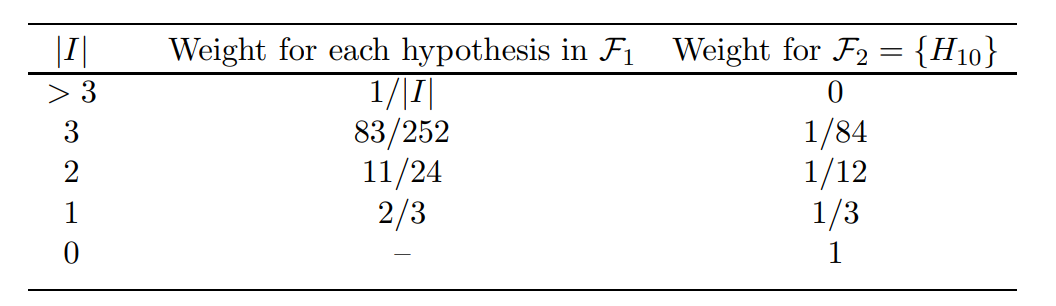

<small>**Таблица 4.** Весовые коэффициенты для процедуры запутанного графа, используемой для анализа исследования на основе PreRELAX-AHF. Здесь $|I|$ обозначает количество неподтвержденных гипотез в $\mathcal{F}_1$.</small>


**Применение графических процедур и симуляция мощности**

Поскольку в реальном исследовании наблюдались значимые эффекты (6 из 9 конечных точек были значимы на одностороннем уровне 0.1), авторы провели симуляцию, чтобы сравнить мощность различных процедур контроля ошибок, со следующими параметрами:

* Истинные средние и стандартные отклонения взяты из Delorme et al. (2016).
* Предполагается многомерное нормальное распределение тестовых статистик с общей корреляцией $\rho$ между конечными точками.
* Уровень значимости $\alpha = 0.1$ (односторонний).
* Для дополненных процедур параметр $\delta = 1$.
* 10 000 независимых повторений.

Результаты представлены в Таблице 5:

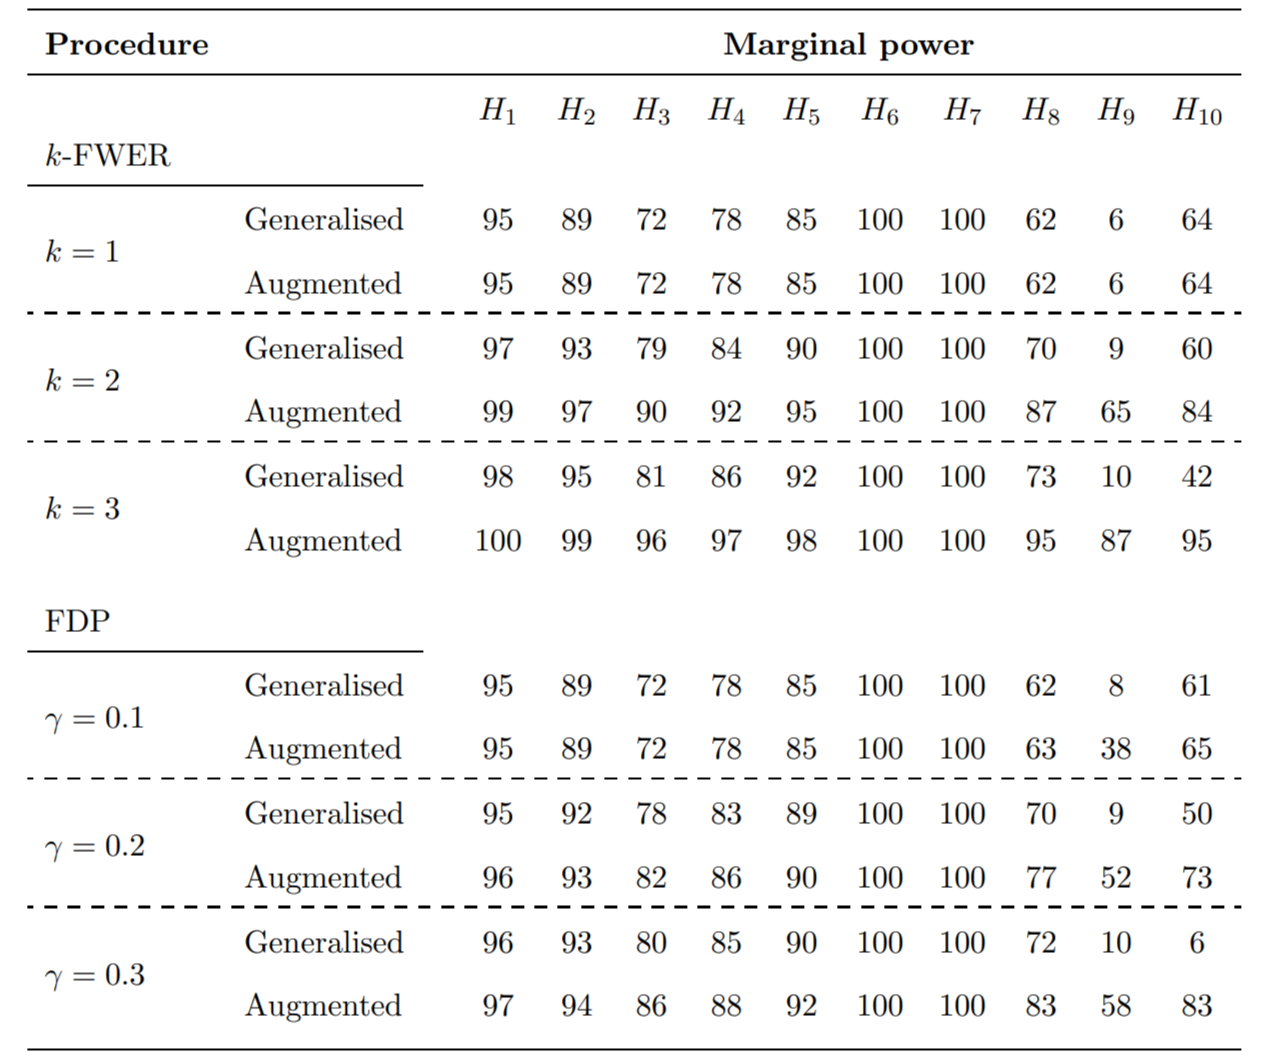

<small>**Таблица 5.** Симулированная маргинальная мощность отвержения каждой из 10 гипотез в дизайне Pre‑RELAX‑AHF. $H_9$ — истинная нулевая гипотеза ($\mu^C_9 = \mu^E_9 = 0.07$\).</small>

**Обсуждение результатов**

1. **Мощность для истинных эффектов.** Гипотезы $H_1$–$H_8$ соответствуют конечным точкам, где ожидается реальный эффект. При обычном FWER мощность колеблется от 0.47 до 0.81. Ослабление контроля до $k=2$ или $\gamma=0.2$ повышает мощность на 3–6 процентных пунктов для дополненной процедуры. При $k=3$ или $\gamma=0.3$ прирост достигает 8–10 пунктов. Это демонстрирует, что даже умеренное ослабление FWER даёт ощутимое улучшение чувствительности.

2. **Контроль ошибки I рода для $H_9$.** $H_9$ — истинная нулевая гипотеза. При $k=1$ её мощность (т.е. вероятность ложного отвержения) составляет 0.06, что ниже номинального $\alpha=0.1$ из‑за консервативности бонферрониевского теста и перераспределения уровней. При $k=2,3$ у обобщённой процедуры ошибка остаётся ниже 0.1 (0.08–0.10), тогда как у дополненной слегка превышает номинал (0.10–0.12). Это ожидаемо: дополненная процедура «добирает» отверждения без строгого контроля FWER для каждой индивидуальной гипотезы, но k‑FWER (вероятность $\ge k$ ложных) остаётся под контролем. В данном случае $k=2$ или $k=3$, и единичная ошибка для $H_9$ допустима.

3. **Мощность для вторичной гипотезы $H_{10}$.** $H_{10}$ имеет начальный вес 0 и может быть отвергнута только при условии успеха 6 из 9 первичных. При $k=1$ мощность составляет 0.12. При переходе к $k=2,3$ у **обобщённой** процедуры мощность **падает** до 0.08–0.10! Это проявление проблемы доноров: $H_{10}$ имеет только одного «коллективного» донора (группу первичных гипотез), и при увеличении $k$ обобщённая процедура не может эффективно передать ей уровень. Дополненная процедура, напротив, повышает мощность $H_{10}$ до 0.13–0.15, поскольку на втором этапе «щедрый» $\delta$ позволяет отвергнуть $H_{10}$, если она оказывается среди наименее значимых оставшихся гипотез.

4. **Сравнение процедур.** Как и в предыдущем кейсе, дополненная процедура демонстрирует систематическое преимущество: для всех гипотез и всех уровней $k,\gamma$ её мощность не ниже, а часто и выше, чем у обобщённой. Особенно заметен выигрыш для гипотез с ограниченным числом доноров ($H_9, H_{10}$).

**Заключение по кейсу**

Исследование Pre‑RELAX‑AHF иллюстрирует несколько важных аспектов:

- **Запутанные графы** позволяют реализовать сложные логические условия типа «K из N», не покидая рамок графического подхода и сохраняя строгий контроль ошибок.
- Даже в таких комплексных дизайнах **дополненные процедуры** обеспечивают прирост мощности по сравнению с обычным FWER и превосходят обобщённые процедуры, которые страдают от структурных ограничений графа.
- Разведочный характер исследования оправдывает использование k‑FWER или FDP: небольшое увеличение доли ложных находок среди вторичных или слабых первичных конечных точек приемлемо, если это позволяет увереннее детектировать реальные эффекты и принимать обоснованные решения о дальнейшей разработке препарата.

### 6.3. ATMOSPHERE study

**Контекст исследования**

ATMOSPHERE (Aliskiren Trial to Minimize Outcomes in Patients with Heart failure) — это крупное подтверждающее клиническое исследование фазы III у пациентов с хронической сердечной недостаточностью. В нём сравнивались три терапевтические стратегии:

* **C** — комбинированная терапия алискирен + эналаприл,
* **A** — монотерапия алискиреном,
* **E** — монотерапия эналаприлом (активный контроль).

Исследование преследовало две основные цели: доказать, что комбинация не уступает (non‑inferior) эналаприлу, и что алискирен не уступает эналаприлу. Дополнительно проверялись две группы вторичных конечных точек (по два показателя в каждой). Итого иерархия включала три уровня:

1. Первичные гипотезы:
   * $H_1$: не меньшая эффективность C против E.
   * $H_2$: не меньшая эффективность A против E.
   * $H_3$: не меньшая эффективность C против A.

2. Вторичное семейство для сравнения C vs E: две конечные точки $\mathcal{H}_4 = \{H_{41}, H_{42}\}$.
3. Вторичное семейство для сравнения A vs E: две конечные точки $\mathcal{H}_5 = \{H_{51}, H_{52}\}$.

Иерархия была следующей: сначала тестируются первичные гипотезы в указанном порядке ($H_1, H_2, H_3$). Если $H_1$ отвергнута, можно переходить к $\mathcal{H}_4$; если $H_2$ — к $\mathcal{H}_5$. Однако полный вес $α$ переходит во вторичное семейство только когда **все** гипотезы внутри данного сравнения отвергнуты. Внутри каждого вторичного семейства применяется процедура Холма.

ㅤ

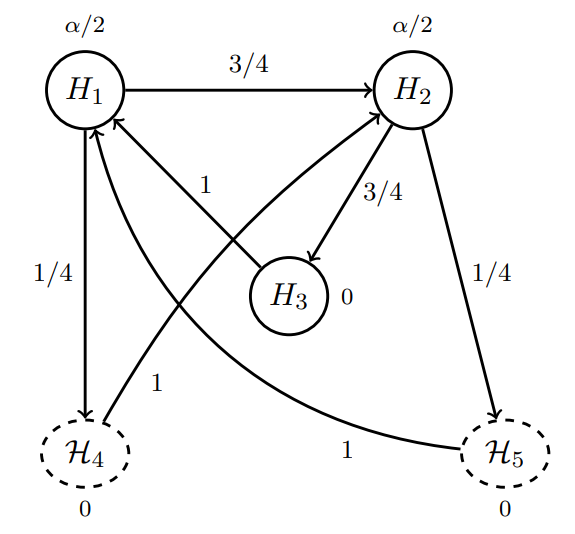

<small>**Рис. 4** Graphical test procedure for the ATMOSPHERE study.</small>

Для иллюстрации авторы задали гипотетические наблюдаемые p‑значения (Maurer & Bretz, 2014):

$$
p_1 = 0.1,\quad p_2 = 0.007,\quad p_3 = 0.05,\quad p_{41}=0.0015,\quad p_{42}=0.04,\quad p_{51}=0.0031,\quad p_{52}=0.001
$$
при общем $\alpha = 0.025$ (односторонний уровень, типичный для подтверждающих испытаний).

**Применение дополненных процедур для k‑FWER и FDP**

Авторы демонстрируют, как дополненные процедуры могли бы повысить мощность в этом сценарии.

**Контроль k‑FWER с $k=2$ ($\alpha=0.025$).** После первого этапа (FWER) отвергнуты три гипотезы. Так как $k=2$, а $|R|=3 \ge 2$, формально условие уже выполнено, и второй этап не требуется. Однако авторы ради иллюстрации показывают, что если бы первичных отвержений было меньше, можно было бы добавить ещё одно. В нашем случае мы просто принимаем результат первого этапа.

**Контроль FDP с $\gamma = 0.3$.** Здесь интереснее. После первого этапа $|R|=3$. Вычисляем максимальное $D$ такое, что $D/(D+3) \le 0.3$. Наибольшее целое $D=1$, значит, можно сделать одно дополнительное отверждение.

Запускаем второй этап с $\delta$ (например, \(\delta=0.5\) или \(\delta=1\)) на обновлённом графе. На правой панели Рис. 4 видно, что после первого этапа ненулевые веса имеют \(H_1\) (0.025), \(H_3\) (0), \(H_{41}, H_{42}\) (0). Дополнительное отверждение получает гипотеза с наименьшим отношением $p/\alpha$ среди оставшихся с положительным $\alpha$. Единственный кандидат — $H_1$ с $p_1=0.1$ и $\alpha_1=0.025$, но даже при $\delta = 1$ порог для $H_1$ становится $1 \times 0.025 = 0.025$, что всё равно меньше 0.1. Так что $H_1$ не отвергается даже на втором этапе. В данном примере дополнительных отверждений не происходит, и итоговый набор остаётся $\{H_2, H_{51}, H_{52}\}$.

Авторы замечают, что при других значениях $p$‑значений (например, если бы $p_1$ было меньше) дополненная процедура позволила бы отвергнуть $H_1$ и затем, возможно, передать уровень в $\mathcal{H}_4$.

**Сравнение с обобщённой процедурой**

Обобщённая процедура для k‑FWER с $k=2$ дала бы ещё более скромный результат. На первом шаге (с порогом $2\alpha$) отвергается только $H_2$. Поскольку $|R|=1 < k$, процедура останавливается. Итого отвергнута только одна гипотеза — меньше, чем при обычном FWER! Это ещё один пример вреда проблемы доноров в иерархических графах. Обобщённая процедура для FDP последовательно запускала бы 1‑FWER, затем 2‑FWER, и в данном случае остановилась бы после 1‑FWER, снова дав лишь одно отвержение.

**Обсуждение и выводы**

Кейс ATMOSPHERE иллюстрирует несколько важных моментов:

1. **Иерархические графы с несколькими семействами** естественно возникают в подтверждающих испытаниях и легко реализуются графическим методом.
2. **Обычный FWER‑тест** успешно перераспределяет уровни между семействами, позволяя тестировать вторичные конечные точки, если первичные значимы. В данном примере отвергнуто три гипотезы, включая обе вторичные для сравнения A vs E.
3. **Дополненные процедуры** могут дать дополнительные отверждения, если после первого этапа остаются гипотезы с достаточно малыми p‑значениями. В нашем конкретном числовом примере эффекта не было, но сама логика сохраняется.
4. **Обобщённые процедуры** в таких иерархических структурах часто дают даже меньше отверждений, чем обычный FWER, из‑за проблемы доноров. Это делает их малопривлекательными для практического использования в сложных дизайнах.
5. **Практическая рекомендация:** в подтверждающих испытаниях со сложной иерархией (несколько первичных, несколько вторичных семейств) предпочтительно использовать либо классический графический FWER‑тест, либо, если допустимо ослабление контроля, дополненную процедуру для k‑FWER/FDP. Обобщённую процедуру следует применять с большой осторожностью, убедившись, что все гипотезы имеют достаточное число доноров.

## 7. Сравнительный анализ и практические рекомендации

Мы прошли большой путь — от простой поправки Бонферрони до обобщённых графических процедур, контролирующих k‑FWER и FDP. Теперь пора подвести итоги и дать практические ориентиры: когда стоит применять графический подход, в чём его сильные стороны, где скрываются подводные камни и какие направления остаются открытыми.

### 7.1 Когда выбирать графический подход

Графический подход является мощным, но не универсальным инструментом. Его применение оправдано, когда выполняются следующие условия:

1. **Иерархическая или логическая структура гипотез.**  
   Если ваши гипотезы естественно группируются в первичные и вторичные семейства, образуют цепочки «от более важных к менее важным» или подчиняются логике «K из N» — графический подход незаменим. Он позволяет закодировать эту структуру в топологии графа, что невозможно сделать с помощью плоских процедур вроде Холма или Бенджамини–Хохберг.

2. **Необходимость прозрачной коммуникации с нестатистиками.**  
   Граф можно нарисовать на доске и обсудить с клинической командой, продакт‑менеджерами или регуляторами. Визуализация гораздо нагляднее, чем таблицы весов для сотен пересечений гипотез. Это особенно важно в клинических испытаниях, где дизайн должен быть одобрен регуляторными органами.

3. **Потребность в «рециклинге» уровня значимости.**  
   В сложных A/B‑тестах мы не хотим «терять» уровень отвергнутой гипотезы — мы хотим передавать его другим, ещё не проверенным. Графический подход с рёбрами и весами делает этот рециклинг явным и автоматическим.

4. **Необходимость строгого контроля FWER (или k‑FWER/FDP) при произвольной зависимости.**  
   Все процедуры, основанные на взвешенном Бонферрони, не требуют никаких предположений о структуре зависимости p‑значений. Это даёт универсальную гарантию контроля ошибок.

Если же ваши гипотезы независимы (или слабо зависимы), и никакой иерархии нет, возможно, более простые методы (например, Бенджамини–Хохберг) дадут более высокую мощность при контроле FDR.

### 7.2 «Подводные камни» и направления развития


#### Известные проблемы

1. **Проблема доноров в обобщённой процедуре.**  
   Мы подробно обсуждали её в разделе 4.1.2. Если гипотеза имеет менее $k$ доноров, обобщённая процедура не может увеличить её вес после отвержения других гипотез. В иерархических графах это приводит к катастрофической потере мощности. Дополненная процедура лишена этого недостатка, поэтому рекомендуется именно она.

2. **Вычислительная сложность обобщённых процедур при больших $m$ и $k>1$.**  
   Алгоритм обобщенных процедур требует перебора подмножеств размера $k-1$ из множества отвергнутых гипотез $R$. При $|R| \approx m$ и больших $k$ число комбинаций $\binom{|R|}{k-1}$ делает вычисления нереализуемыми. В статье предложены упрощённые варианты, но они дают лишь асимптотический контроль и всё равно требуют аккуратной реализации. Дополненные процедуры, напротив, имеют линейную сложность.

3. **Отсутствие скорректированных $p$‑значений для дополненных процедур.**  
   В классическом графическом подходе можно вычислить adjusted p‑value для каждой гипотезы — это позволяет легко применять тест при любом $\alpha$. Для дополненной процедуры аналогичный аппарат пока не разработан. Приходится запускать тест заново для каждого интересующего $\alpha$, что замедляет анализ чувствительности. Это открытая methodological задача.

#### Направления развития

- **Интеграция с машинным обучением.** Автоматическое построение оптимального графа по историческим данным (например, оценка матрицы переходов, максимизирующей мощность при ограничениях на FWER).
- **Байесовские графические процедуры.** Адаптация идей graphical approach к задачам с априорными распределениями, где контролируется posterior probability ошибок.
- **Унификация с FDR‑контролем.** Разработка графических процедур, контролирующих FDR в конечной выборке, а не только асимптотически.
- **Расширение на многомерные параметрические тесты.** Разработка устойчивых методов проверки монотонности для произвольных ковариационных матриц, чтобы можно было безопасно применять параметрический графический подход в любых A/B‑тестах.
- **Онлайн‑мониторинг и непрерывный анализ.**  
   В современных A/B‑экспериментах всё чаще применяется непрерывный мониторинг (continuous monitoring) с ранней остановкой при достижении значимости. Графический подход в текущем виде ориентирован на фиксированное число проверок (или групповые последовательные дизайны с заранее заданными моментами анализа). Перенос графических процедур на полностью онлайн‑режим (например, с использованием always‑valid p‑values) — актуальное направление исследований.